In [1]:
# ============================================================
# STEP 1: IMPORT LIBRARIES AND LOAD DATA
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

# Load the dataset
DATA_PATH = os.path.join('..', '..', 'Dataset', 'DelhiveryDataset', 'DataCoSupplyChainDataset.csv') 
df = pd.read_csv(DATA_PATH, encoding='latin-1')

print("="*80)
print("DATASET SHAPE")
print("="*80)
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

print("\n" + "="*80)
print("FIRST 5 ROWS")
print("="*80)
print(df.head())

print("\n" + "="*80)
print("DATA TYPES & NON-NULL COUNTS")
print("="*80)
print(df.info())

print("\n" + "="*80)
print("STATISTICAL SUMMARY")
print("="*80)
print(df.describe())

print("\n" + "="*80)
print("MISSING VALUES")
print("="*80)
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing': missing, 'Percentage': missing_pct})
print(missing_df[missing_df['Missing'] > 0].sort_values('Percentage', ascending=False))

DATASET SHAPE
Rows: 180,519
Columns: 53

FIRST 5 ROWS
       Type  Days for shipping (real)  Days for shipment (scheduled)  \
0     DEBIT                         3                              4   
1  TRANSFER                         5                              4   
2      CASH                         4                              4   
3     DEBIT                         3                              4   
4   PAYMENT                         2                              4   

   Benefit per order  Sales per customer   Delivery Status  \
0             91.250             314.640  Advance shipping   
1           -249.090             311.360     Late delivery   
2           -247.780             309.720  Shipping on time   
3             22.860             304.810  Advance shipping   
4            134.210             298.250  Advance shipping   

   Late_delivery_risk  Category Id   Category Name Customer City  \
0                   0           73  Sporting Goods        Caguas   
1   

In [2]:
# ============================================================
# STEP 2: DATA CLEANING
# ============================================================

print("="*80)
print("DATA CLEANING PROCESS")
print("="*80)

# --- 2.1 Check duplicates ---
duplicates = df.duplicated().sum()
print(f"\nDuplicate rows: {duplicates}")

# --- 2.2 Drop irrelevant/PII columns ---
cols_to_drop = [
    'Customer Email', 'Customer Password', 'Customer Fname', 'Customer Lname',
    'Customer Street', 'Customer Zipcode', 'Order Zipcode', 'Product Description',
    'Product Image', 'Order Item Id', 'Order Item Cardprod Id', 'Customer Id',
    'Order Customer Id', 'Order Id', 'Product Card Id', 'Category Id',
    'Department Id', 'Order Item Product Price'
]

df_clean = df.drop(columns=[c for c in cols_to_drop if c in df.columns])
print(f"\nDropped {len(cols_to_drop)} irrelevant columns")
print(f"Remaining columns: {df_clean.shape[1]}")

# --- 2.3 Handle date columns ---
df_clean['order date (DateOrders)'] = pd.to_datetime(df_clean['order date (DateOrders)'])
df_clean['shipping date (DateOrders)'] = pd.to_datetime(df_clean['shipping date (DateOrders)'])

# --- 2.4 Remove rows with critical missing values ---
critical_cols = ['Delivery Status', 'Late_delivery_risk', 'Days for shipping (real)',
                 'Days for shipment (scheduled)', 'Sales', 'Order Item Quantity']

before = len(df_clean)
df_clean = df_clean.dropna(subset=critical_cols)
after = len(df_clean)
print(f"\nRemoved {before - after} rows with missing critical values")

# --- 2.5 Handle outliers in Sales and Benefit ---
def remove_outliers_iqr(data, col, factor=3.0):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - factor * IQR
    upper = Q3 + factor * IQR
    return data[(data[col] >= lower) & (data[col] <= upper)]

for col in ['Sales', 'Benefit per order', 'Order Item Total']:
    before = len(df_clean)
    df_clean = remove_outliers_iqr(df_clean, col)
    print(f"  {col}: removed {before - len(df_clean)} outliers")

print(f"\nFinal cleaned dataset: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns")

DATA CLEANING PROCESS

Duplicate rows: 0

Dropped 18 irrelevant columns
Remaining columns: 35

Removed 0 rows with missing critical values
  Sales: removed 467 outliers
  Benefit per order: removed 7657 outliers
  Order Item Total: removed 0 outliers

Final cleaned dataset: 172,395 rows × 35 columns


In [4]:
# ============================================================
# STEP 3: FEATURE ENGINEERING
# ============================================================

print("="*80)
print("FEATURE ENGINEERING")
print("="*80)

# --- 3.1 Shipping delay features ---
df_clean['Shipping_Delay'] = (df_clean['Days for shipping (real)'] -
                               df_clean['Days for shipment (scheduled)'])
df_clean['Is_Late'] = (df_clean['Shipping_Delay'] > 0).astype(int)
df_clean['Delay_Ratio'] = df_clean['Days for shipping (real)'] / (
    df_clean['Days for shipment (scheduled)'] + 1)
df_clean['Shipping_Efficiency'] = df_clean['Days for shipment (scheduled)'] / (
    df_clean['Days for shipping (real)'] + 1)

# --- 3.2 Temporal features ---
df_clean['Order_Year'] = df_clean['order date (DateOrders)'].dt.year
df_clean['Order_Month'] = df_clean['order date (DateOrders)'].dt.month
df_clean['Order_Day'] = df_clean['order date (DateOrders)'].dt.day
df_clean['Order_DayOfWeek'] = df_clean['order date (DateOrders)'].dt.dayofweek
df_clean['Order_Hour'] = df_clean['order date (DateOrders)'].dt.hour
df_clean['Order_Quarter'] = df_clean['order date (DateOrders)'].dt.quarter
df_clean['Is_Weekend'] = (df_clean['Order_DayOfWeek'] >= 5).astype(int)

# --- 3.3 Financial features ---
df_clean['Profit_Margin'] = df_clean['Order Profit Per Order'] / (
    df_clean['Sales'] + 1)
df_clean['Discount_Amount'] = df_clean['Order Item Discount']
df_clean['Is_Discounted'] = (df_clean['Order Item Discount'] > 0).astype(int)
df_clean['High_Value_Order'] = (df_clean['Sales'] > df_clean['Sales'].median()).astype(int)

# --- 3.4 Shipping mode features ---
shipping_mode_map = {'Standard Class': 0, 'Second Class': 1, 'First Class': 2, 'Same Day': 3}
df_clean['Shipping_Mode_Enc'] = df_clean['Shipping Mode'].map(shipping_mode_map).fillna(0)

# --- 3.5 Aggregated features ---
customer_agg = df_clean.groupby('Customer Segment').agg(
    Avg_Sales=('Sales', 'mean'),
    Avg_Delay=('Shipping_Delay', 'mean')
).reset_index()
customer_agg.columns = ['Customer Segment', 'Segment_Avg_Sales', 'Segment_Avg_Delay']
df_clean = df_clean.merge(customer_agg, on='Customer Segment', how='left')

market_agg = df_clean.groupby('Market').agg(
    Market_Avg_Delay=('Shipping_Delay', 'mean'),
    Market_Late_Rate=('Is_Late', 'mean')
).reset_index()
df_clean = df_clean.merge(market_agg, on='Market', how='left')

print("\nNew features created:")
new_features = ['Shipping_Delay', 'Is_Late', 'Delay_Ratio', 'Shipping_Efficiency',
                'Order_Year', 'Order_Month', 'Order_Day', 'Order_DayOfWeek',
                'Order_Hour', 'Order_Quarter', 'Is_Weekend', 'Profit_Margin',
                'Discount_Amount', 'Is_Discounted', 'High_Value_Order',
                'Shipping_Mode_Enc', 'Segment_Avg_Sales', 'Segment_Avg_Delay',
                'Market_Avg_Delay', 'Market_Late_Rate']
for f in new_features:
    print(f"  -> {f}")

print(f"\nFinal dataset shape: {df_clean.shape}")

FEATURE ENGINEERING

New features created:
  -> Shipping_Delay
  -> Is_Late
  -> Delay_Ratio
  -> Shipping_Efficiency
  -> Order_Year
  -> Order_Month
  -> Order_Day
  -> Order_DayOfWeek
  -> Order_Hour
  -> Order_Quarter
  -> Is_Weekend
  -> Profit_Margin
  -> Discount_Amount
  -> Is_Discounted
  -> High_Value_Order
  -> Shipping_Mode_Enc
  -> Segment_Avg_Sales
  -> Segment_Avg_Delay
  -> Market_Avg_Delay
  -> Market_Late_Rate

Final dataset shape: (172395, 59)


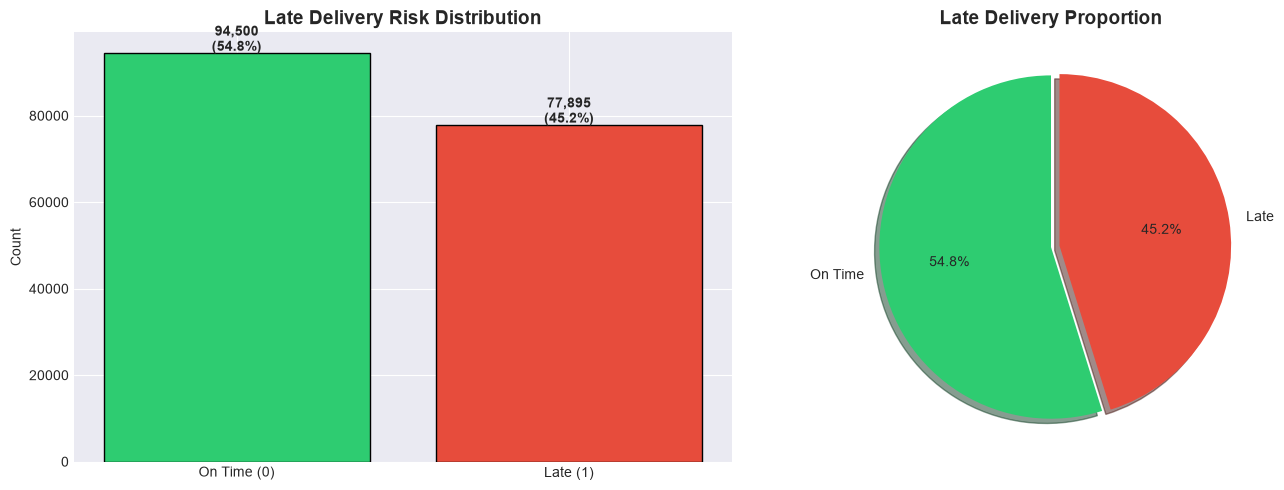

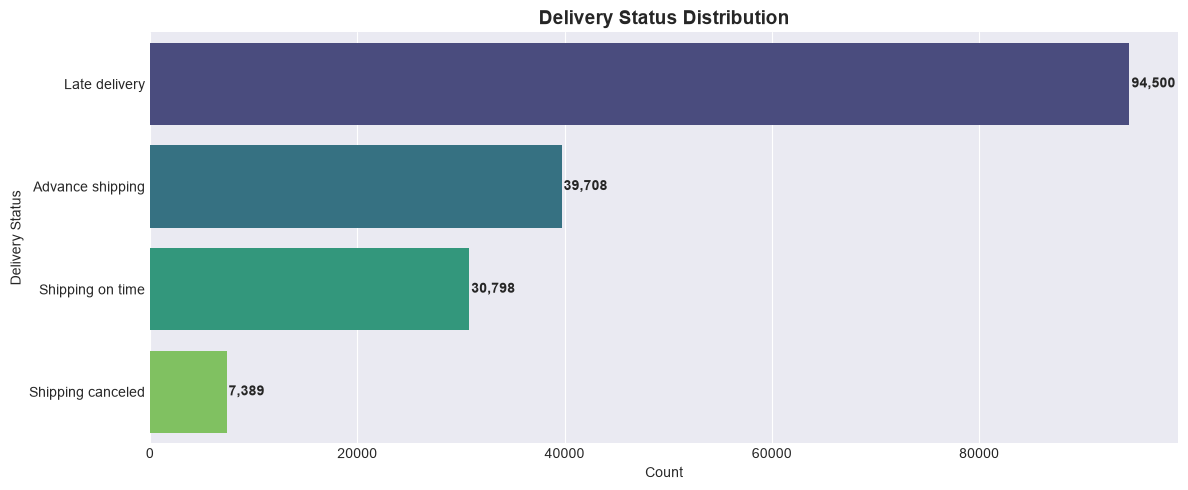

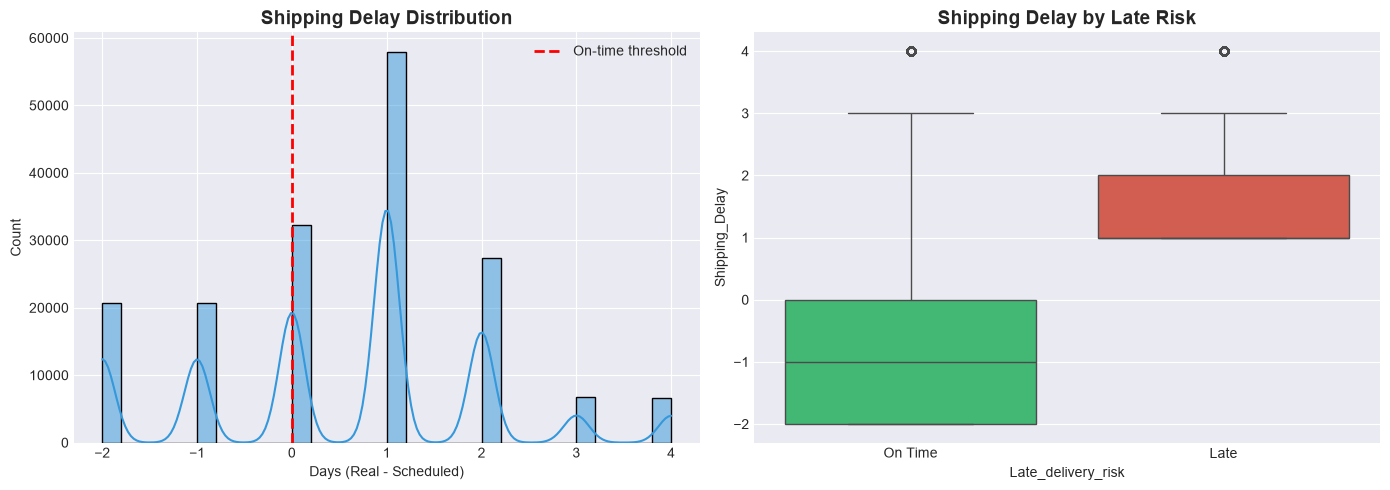

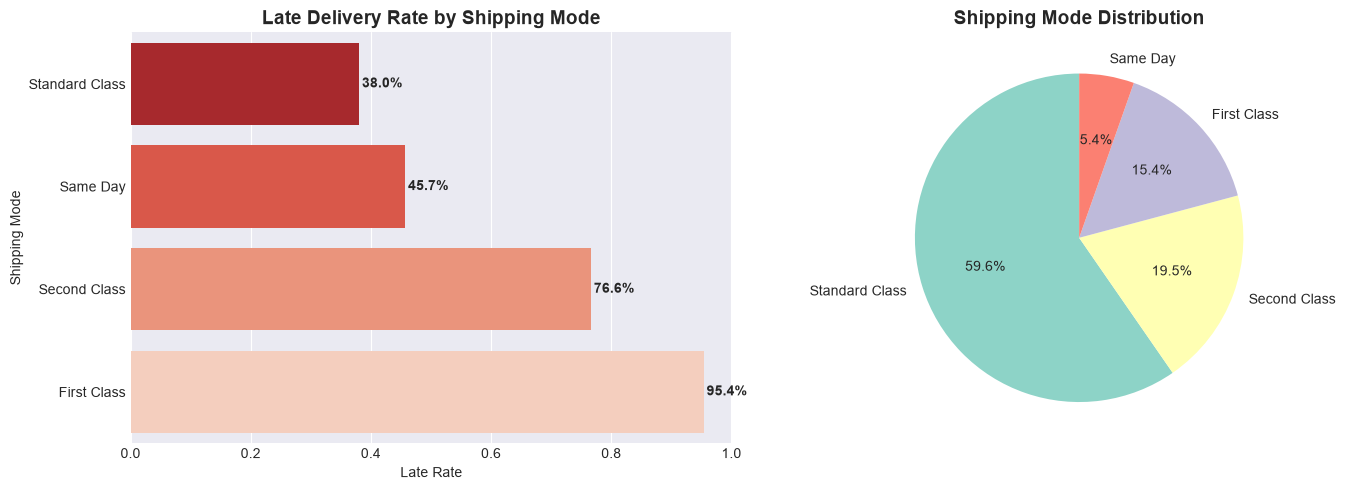

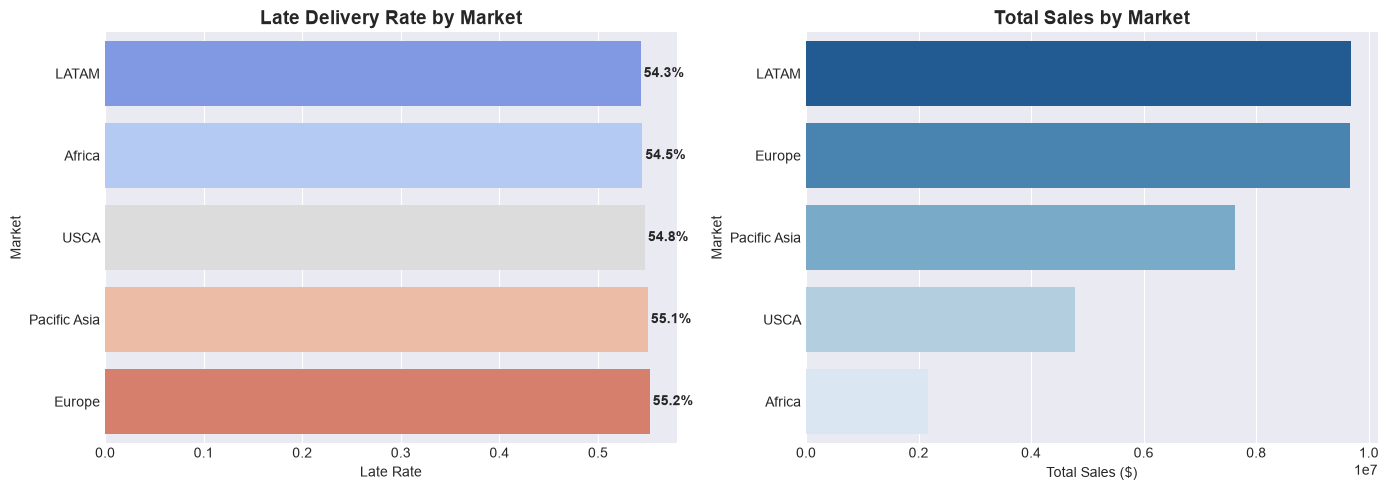

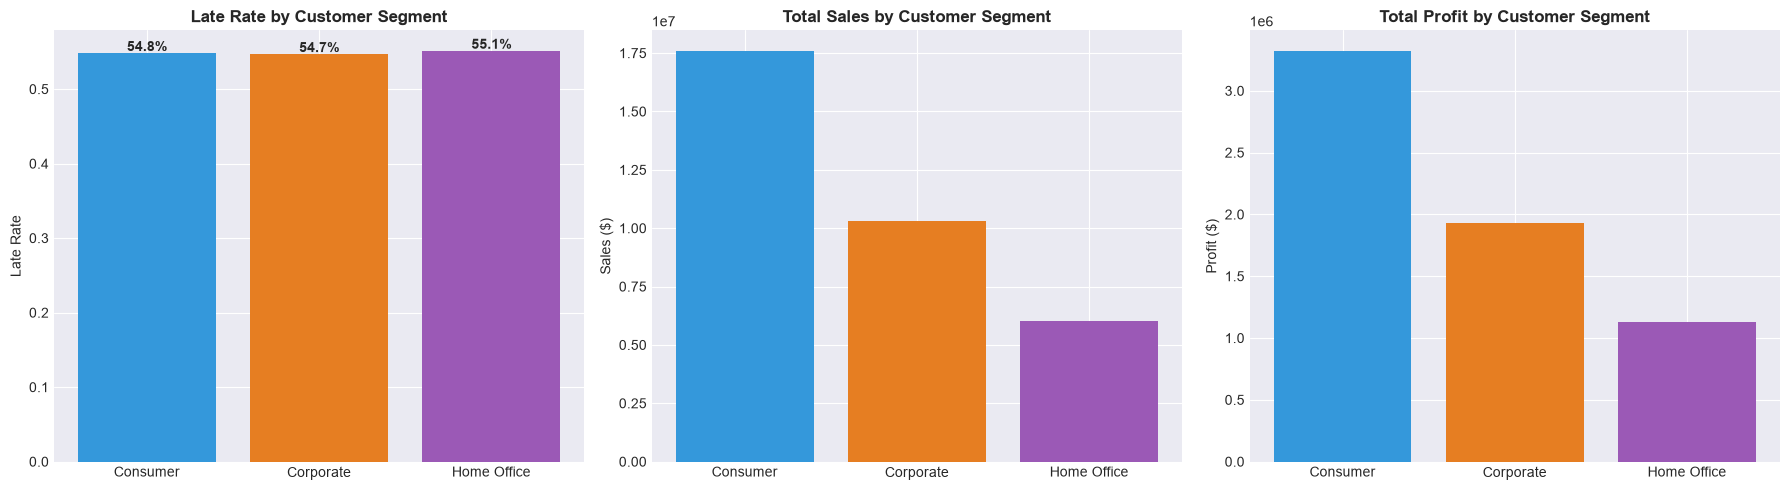

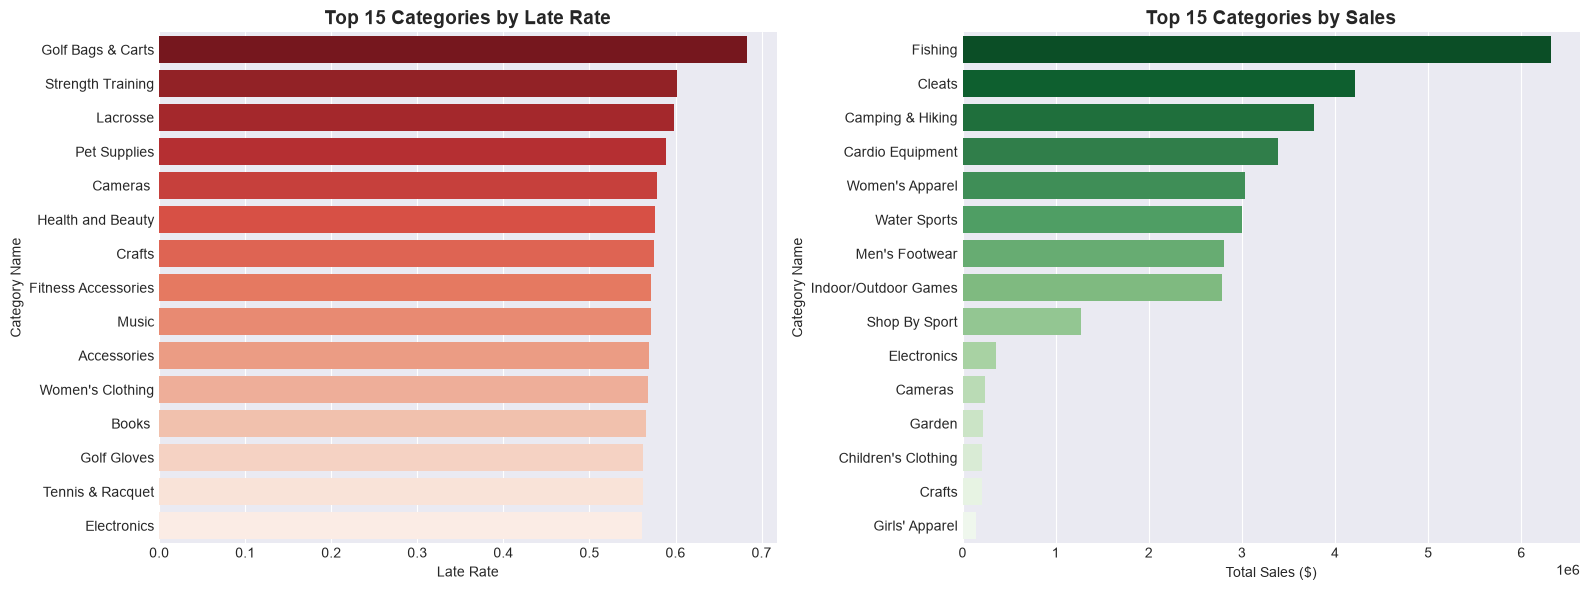

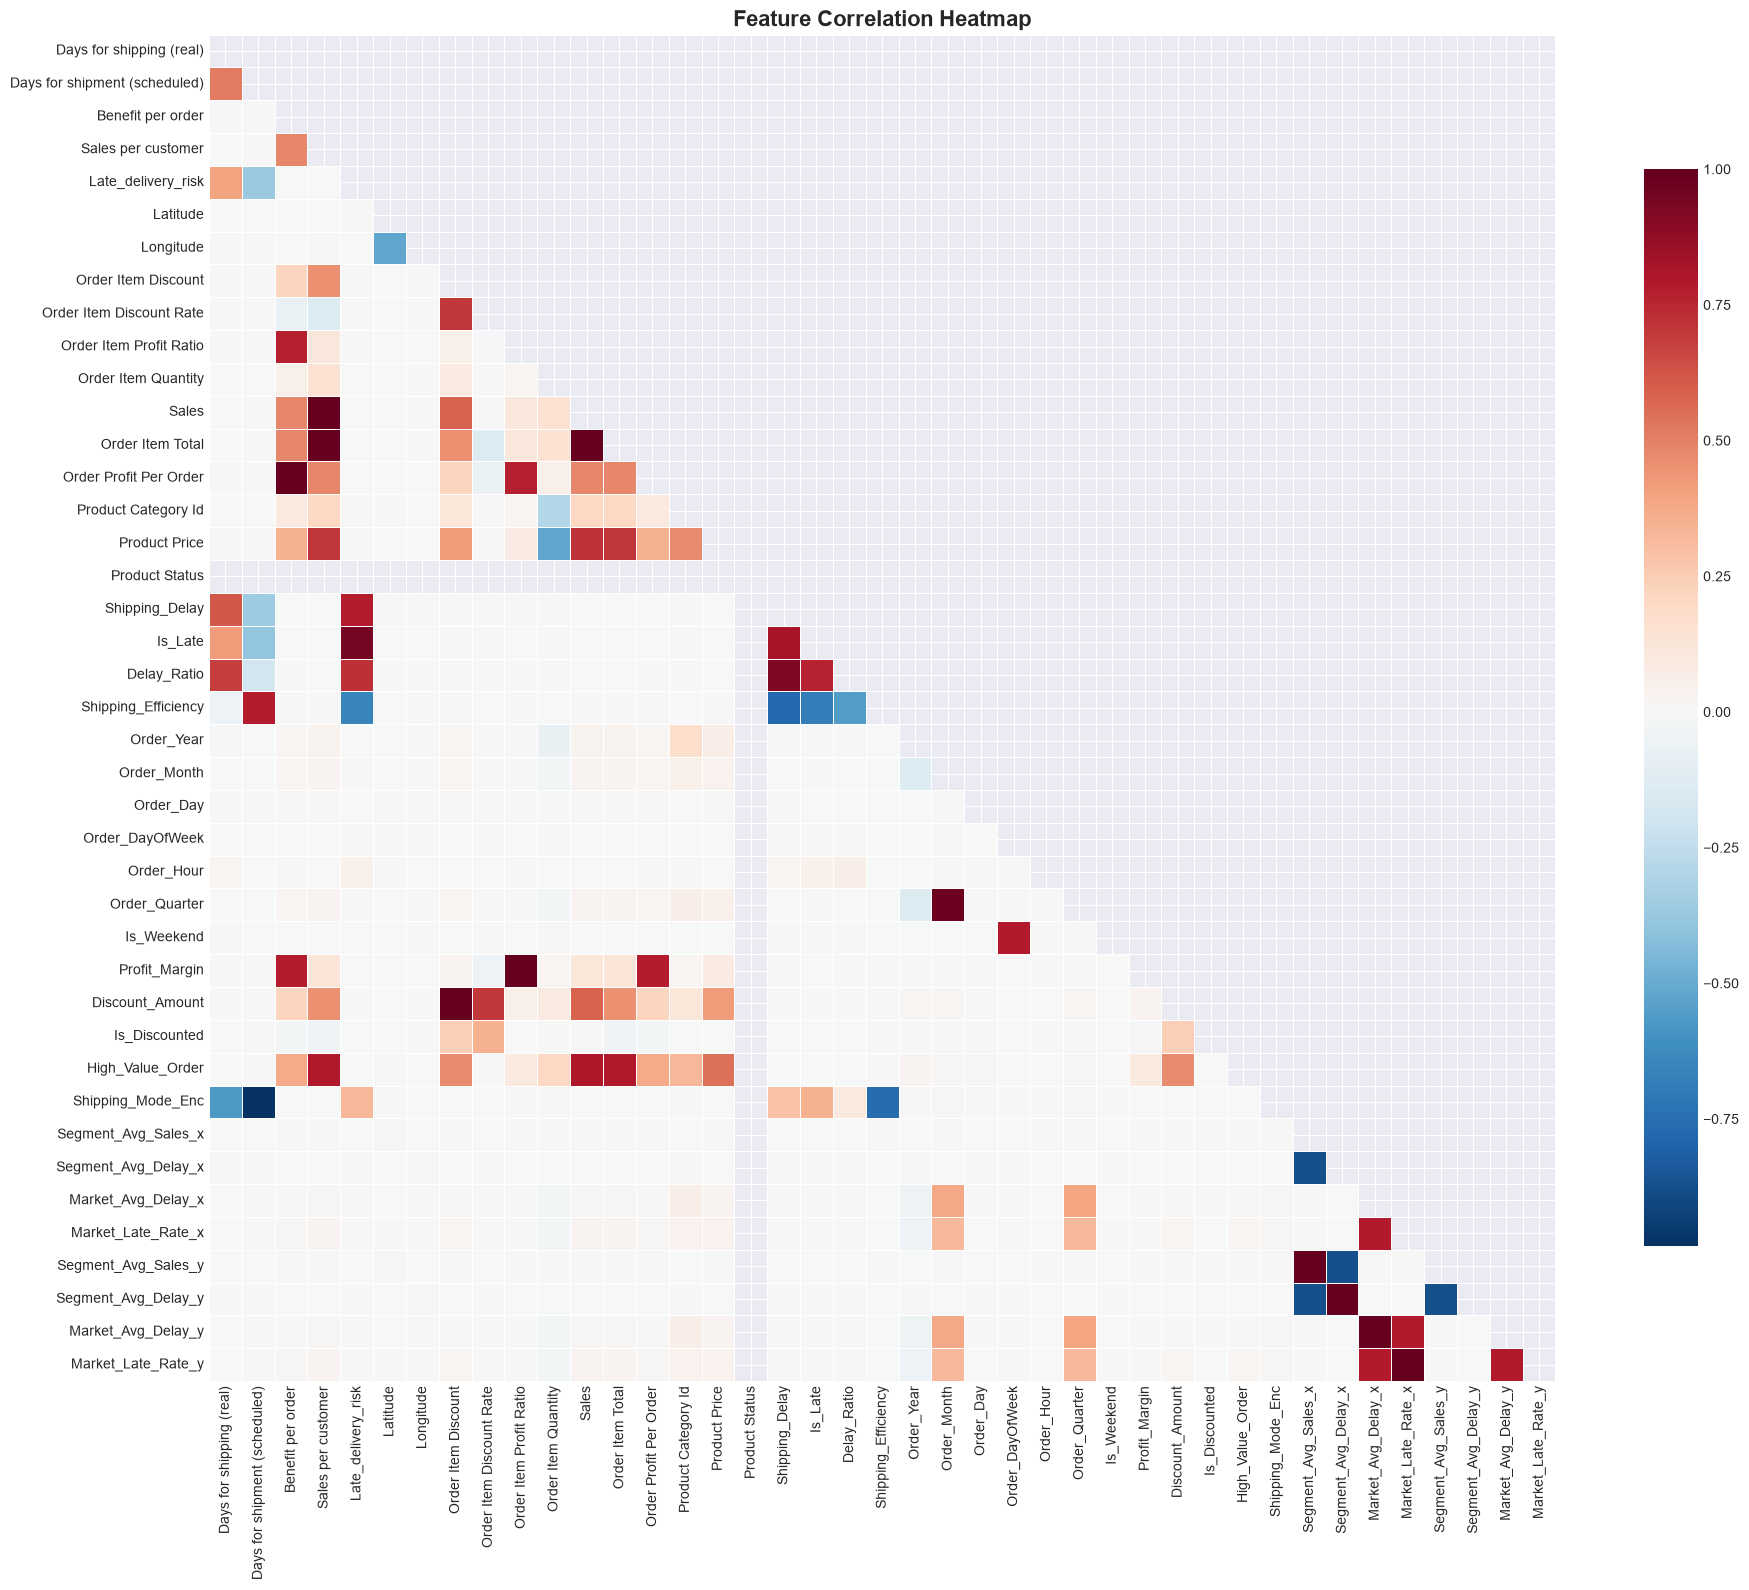


TOP 20 FEATURES CORRELATED WITH LATE DELIVERY RISK
Is_Late                          0.952
Shipping_Delay                   0.778
Delay_Ratio                      0.725
Shipping_Efficiency             -0.655
Days for shipping (real)         0.401
Days for shipment (scheduled)   -0.370
Shipping_Mode_Enc                0.332
Order_Hour                       0.047
Market_Avg_Delay_x               0.007
Market_Avg_Delay_y               0.007
Market_Late_Rate_y               0.007
Market_Late_Rate_x               0.007
Is_Discounted                   -0.004
Order_Month                      0.003
Segment_Avg_Delay_y              0.003
Segment_Avg_Delay_x              0.003
High_Value_Order                -0.003
Segment_Avg_Sales_y             -0.003
Segment_Avg_Sales_x             -0.003
Product Category Id              0.003
Name: Late_delivery_risk, dtype: float64


In [5]:
# ============================================================
# STEP 4: EXPLORATORY DATA ANALYSIS & VISUALIZATION
# ============================================================

# --- 4.1 Target Variable Distribution ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

late_counts = df_clean['Late_delivery_risk'].value_counts()
axes[0].bar(['On Time (0)', 'Late (1)'], late_counts.values,
            color=['#2ecc71', '#e74c3c'], edgecolor='black')
axes[0].set_title('Late Delivery Risk Distribution', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(late_counts.values):
    axes[0].text(i, v + 500, f'{v:,}\n({v/len(df_clean)*100:.1f}%)',
                 ha='center', fontweight='bold')

axes[1].pie(late_counts.values, labels=['On Time', 'Late'],
            autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'],
            explode=(0, 0.05), shadow=True, startangle=90)
axes[1].set_title('Late Delivery Proportion', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 4.2 Delivery Status Distribution ---
fig, ax = plt.subplots(figsize=(12, 5))
status_counts = df_clean['Delivery Status'].value_counts()
sns.barplot(x=status_counts.values, y=status_counts.index, palette='viridis', ax=ax)
ax.set_title('Delivery Status Distribution', fontsize=14, fontweight='bold')
ax.set_xlabel('Count')
for i, v in enumerate(status_counts.values):
    ax.text(v + 200, i, f'{v:,}', va='center', fontweight='bold')
plt.tight_layout()
plt.savefig('delivery_status.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 4.3 Shipping Delay Distribution ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_clean['Shipping_Delay'], bins=30, kde=True,
             color='#3498db', ax=axes[0])
axes[0].axvline(0, color='red', linestyle='--', linewidth=2, label='On-time threshold')
axes[0].set_title('Shipping Delay Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Days (Real - Scheduled)')
axes[0].legend()

sns.boxplot(x='Late_delivery_risk', y='Shipping_Delay',
            data=df_clean, palette=['#2ecc71', '#e74c3c'], ax=axes[1])
axes[1].set_title('Shipping Delay by Late Risk', fontsize=14, fontweight='bold')
axes[1].set_xticklabels(['On Time', 'Late'])
plt.tight_layout()
plt.savefig('shipping_delay.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 4.4 Shipping Mode Analysis ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

mode_late = df_clean.groupby('Shipping Mode')['Late_delivery_risk'].mean().sort_values()
sns.barplot(x=mode_late.values, y=mode_late.index, palette='Reds_r', ax=axes[0])
axes[0].set_title('Late Delivery Rate by Shipping Mode', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Late Rate')
for i, v in enumerate(mode_late.values):
    axes[0].text(v + 0.005, i, f'{v:.1%}', va='center', fontweight='bold')

mode_counts = df_clean['Shipping Mode'].value_counts()
axes[1].pie(mode_counts.values, labels=mode_counts.index, autopct='%1.1f%%',
            colors=sns.color_palette('Set3'), startangle=90)
axes[1].set_title('Shipping Mode Distribution', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('shipping_mode.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 4.5 Market Analysis ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

market_late = df_clean.groupby('Market')['Late_delivery_risk'].mean().sort_values()
sns.barplot(x=market_late.values, y=market_late.index, palette='coolwarm', ax=axes[0])
axes[0].set_title('Late Delivery Rate by Market', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Late Rate')
for i, v in enumerate(market_late.values):
    axes[0].text(v + 0.003, i, f'{v:.1%}', va='center', fontweight='bold')

market_sales = df_clean.groupby('Market')['Sales'].sum().sort_values(ascending=False)
sns.barplot(x=market_sales.values, y=market_sales.index, palette='Blues_r', ax=axes[1])
axes[1].set_title('Total Sales by Market', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Total Sales ($)')
plt.tight_layout()
plt.savefig('market_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 4.6 Customer Segment Analysis ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

seg_late = df_clean.groupby('Customer Segment')['Late_delivery_risk'].mean()
axes[0].bar(seg_late.index, seg_late.values, color=['#3498db', '#e67e22', '#9b59b6'])
axes[0].set_title('Late Rate by Customer Segment', fontweight='bold')
axes[0].set_ylabel('Late Rate')
for i, v in enumerate(seg_late.values):
    axes[0].text(i, v + 0.003, f'{v:.1%}', ha='center', fontweight='bold')

seg_sales = df_clean.groupby('Customer Segment')['Sales'].sum()
axes[1].bar(seg_sales.index, seg_sales.values, color=['#3498db', '#e67e22', '#9b59b6'])
axes[1].set_title('Total Sales by Customer Segment', fontweight='bold')
axes[1].set_ylabel('Sales ($)')

seg_profit = df_clean.groupby('Customer Segment')['Order Profit Per Order'].sum()
axes[2].bar(seg_profit.index, seg_profit.values, color=['#3498db', '#e67e22', '#9b59b6'])
axes[2].set_title('Total Profit by Customer Segment', fontweight='bold')
axes[2].set_ylabel('Profit ($)')
plt.tight_layout()
plt.savefig('segment_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 4.7 Top Categories Analysis ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_cat_late = df_clean.groupby('Category Name')['Late_delivery_risk'].mean().sort_values(ascending=False).head(15)
sns.barplot(x=top_cat_late.values, y=top_cat_late.index, palette='Reds_r', ax=axes[0])
axes[0].set_title('Top 15 Categories by Late Rate', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Late Rate')

top_cat_sales = df_clean.groupby('Category Name')['Sales'].sum().sort_values(ascending=False).head(15)
sns.barplot(x=top_cat_sales.values, y=top_cat_sales.index, palette='Greens_r', ax=axes[1])
axes[1].set_title('Top 15 Categories by Sales', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Total Sales ($)')
plt.tight_layout()
plt.savefig('category_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 4.8 Correlation Heatmap ---
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
corr_matrix = df_clean[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(20, 16))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=False, cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, ax=ax,
            cbar_kws={"shrink": 0.8})
ax.set_title('Feature Correlation Heatmap', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Top correlations with target
target_corr = corr_matrix['Late_delivery_risk'].drop('Late_delivery_risk').sort_values(key=abs, ascending=False)
print("\n" + "="*80)
print("TOP 20 FEATURES CORRELATED WITH LATE DELIVERY RISK")
print("="*80)
print(target_corr.head(20))

BOTTLENECK DETECTION

Overall Late Delivery Rate: 54.82%

------------------------------------------------------------
BOTTLENECK 1: SHIPPING MODE
------------------------------------------------------------
                Total_Orders  Late_Orders  Late_Rate  Avg_Real_Days  \
Shipping Mode                                                         
First Class            26627        25393      0.954          2.000   
Second Class           33634        25768      0.766          3.990   
Same Day                9316         4256      0.457          0.477   
Standard Class        102818        39083      0.380          3.994   

                Avg_Scheduled_Days  
Shipping Mode                       
First Class                  1.000  
Second Class                 2.000  
Same Day                     0.000  
Standard Class               4.000  

------------------------------------------------------------
BOTTLENECK 2: MARKET
------------------------------------------------------------

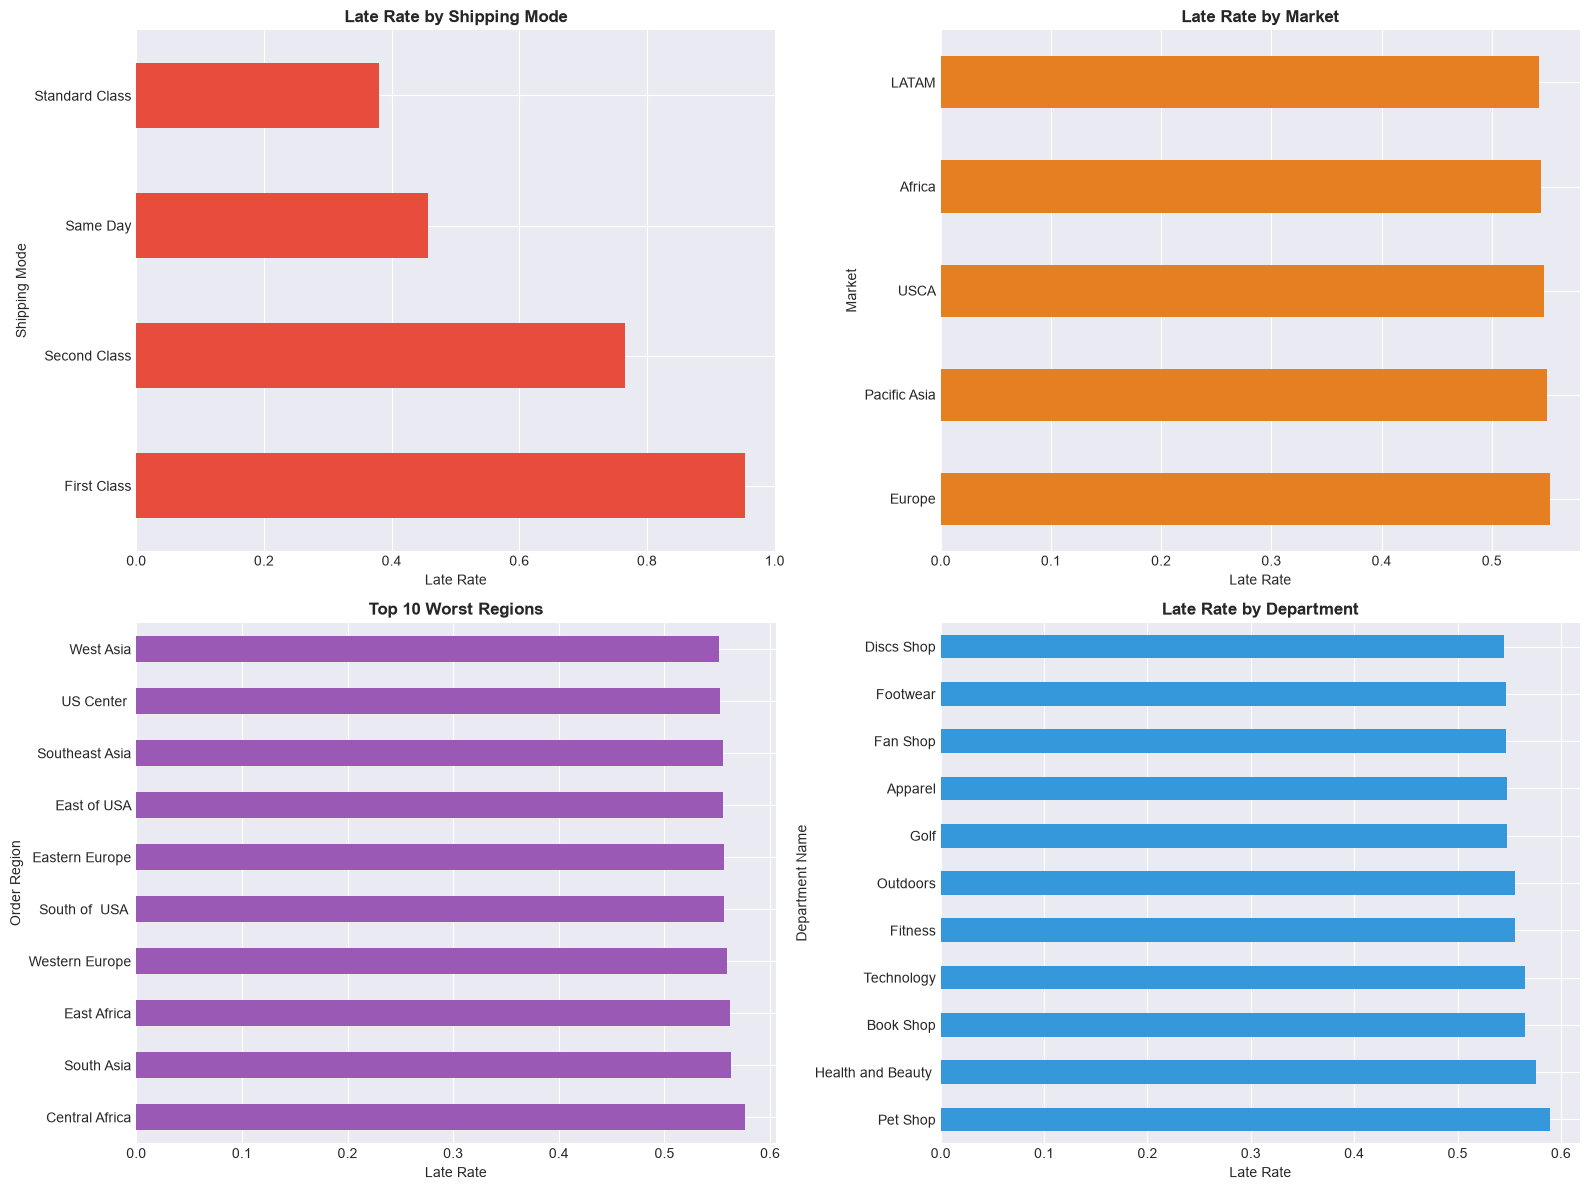

In [6]:
# ============================================================
# STEP 5: BOTTLENECK DETECTION
# ============================================================

print("="*80)
print("BOTTLENECK DETECTION")
print("="*80)

# --- 5.1 Overall Late Delivery Rate ---
overall_late = df_clean['Late_delivery_risk'].mean()
print(f"\nOverall Late Delivery Rate: {overall_late:.2%}")

# --- 5.2 Bottleneck by Shipping Mode ---
print("\n" + "-"*60)
print("BOTTLENECK 1: SHIPPING MODE")
print("-"*60)
mode_analysis = df_clean.groupby('Shipping Mode').agg(
    Total_Orders=('Late_delivery_risk', 'count'),
    Late_Orders=('Late_delivery_risk', 'sum'),
    Late_Rate=('Late_delivery_risk', 'mean'),
    Avg_Real_Days=('Days for shipping (real)', 'mean'),
    Avg_Scheduled_Days=('Days for shipment (scheduled)', 'mean')
).sort_values('Late_Rate', ascending=False)
print(mode_analysis)

# --- 5.3 Bottleneck by Market ---
print("\n" + "-"*60)
print("BOTTLENECK 2: MARKET")
print("-"*60)
market_analysis = df_clean.groupby('Market').agg(
    Total_Orders=('Late_delivery_risk', 'count'),
    Late_Rate=('Late_delivery_risk', 'mean'),
    Avg_Delay=('Shipping_Delay', 'mean'),
    Total_Sales=('Sales', 'sum')
).sort_values('Late_Rate', ascending=False)
print(market_analysis)

# --- 5.4 Bottleneck by Region ---
print("\n" + "-"*60)
print("BOTTLENECK 3: TOP 10 WORST REGIONS")
print("-"*60)
region_analysis = df_clean.groupby('Order Region').agg(
    Total_Orders=('Late_delivery_risk', 'count'),
    Late_Rate=('Late_delivery_risk', 'mean'),
    Avg_Delay=('Shipping_Delay', 'mean')
).sort_values('Late_Rate', ascending=False).head(10)
print(region_analysis)

# --- 5.5 Bottleneck by Department ---
print("\n" + "-"*60)
print("BOTTLENECK 4: DEPARTMENT")
print("-"*60)
dept_analysis = df_clean.groupby('Department Name').agg(
    Total_Orders=('Late_delivery_risk', 'count'),
    Late_Rate=('Late_delivery_risk', 'mean'),
    Avg_Delay=('Shipping_Delay', 'mean')
).sort_values('Late_Rate', ascending=False)
print(dept_analysis)

# --- 5.6 Bottleneck Visualization ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Shipping mode
mode_analysis['Late_Rate'].plot(kind='barh', ax=axes[0, 0], color='#e74c3c')
axes[0, 0].set_title('Late Rate by Shipping Mode', fontweight='bold')
axes[0, 0].set_xlabel('Late Rate')

# Market
market_analysis['Late_Rate'].plot(kind='barh', ax=axes[0, 1], color='#e67e22')
axes[0, 1].set_title('Late Rate by Market', fontweight='bold')
axes[0, 1].set_xlabel('Late Rate')

# Region
region_analysis['Late_Rate'].plot(kind='barh', ax=axes[1, 0], color='#9b59b6')
axes[1, 0].set_title('Top 10 Worst Regions', fontweight='bold')
axes[1, 0].set_xlabel('Late Rate')

# Department
dept_analysis['Late_Rate'].plot(kind='barh', ax=axes[1, 1], color='#3498db')
axes[1, 1].set_title('Late Rate by Department', fontweight='bold')
axes[1, 1].set_xlabel('Late Rate')

plt.tight_layout()
plt.savefig('bottleneck_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

ROOT CAUSE ANALYSIS


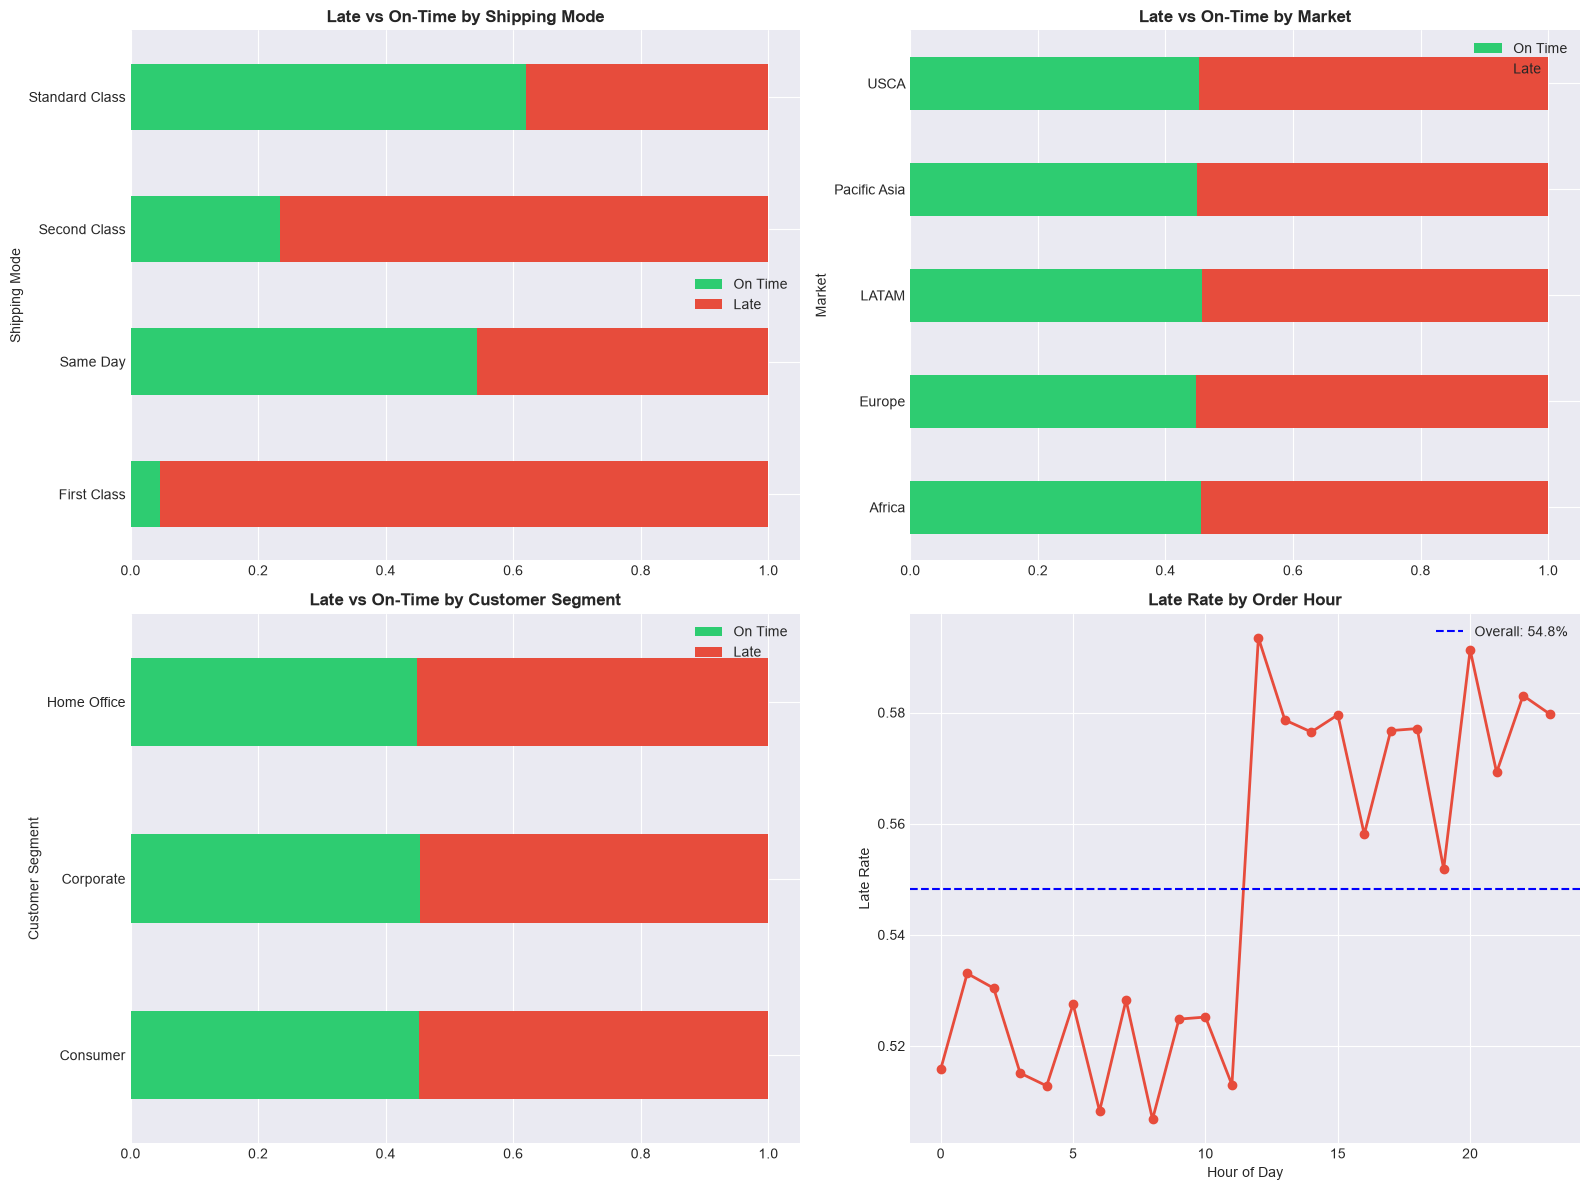


------------------------------------------------------------
FINANCIAL IMPACT OF LATE DELIVERIES
------------------------------------------------------------
                    Total_Profit  Avg_Profit  Total_Sales  Avg_Sales
Late_delivery_risk                                                  
0                    2887402.740      37.068 15344570.327    196.990
1                    3489771.910      36.929 18571780.249    196.527

------------------------------------------------------------
KEY STATISTICAL FINDINGS
------------------------------------------------------------
Average delay for LATE orders: 1.62 days
Average delay for ON-TIME orders: -0.71 days

Most common late delivery statuses:
Delivery Status
Late delivery    94500
Name: count, dtype: int64

Correlation between Shipping Delay and Profit: -0.001


In [7]:
# ============================================================
# STEP 6: ROOT CAUSE ANALYSIS
# ============================================================

print("="*80)
print("ROOT CAUSE ANALYSIS")
print("="*80)

# --- 6.1 What causes late delivery? ---
# Compare late vs on-time across key dimensions
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# By shipping mode
late_by_mode = df_clean.groupby(['Shipping Mode', 'Late_delivery_risk']).size().unstack(fill_value=0)
late_by_mode_pct = late_by_mode.div(late_by_mode.sum(axis=1), axis=0)
late_by_mode_pct.plot(kind='barh', stacked=True, ax=axes[0, 0],
                       color=['#2ecc71', '#e74c3c'])
axes[0, 0].set_title('Late vs On-Time by Shipping Mode', fontweight='bold')
axes[0, 0].legend(['On Time', 'Late'])

# By market
late_by_market = df_clean.groupby(['Market', 'Late_delivery_risk']).size().unstack(fill_value=0)
late_by_market_pct = late_by_market.div(late_by_market.sum(axis=1), axis=0)
late_by_market_pct.plot(kind='barh', stacked=True, ax=axes[0, 1],
                         color=['#2ecc71', '#e74c3c'])
axes[0, 1].set_title('Late vs On-Time by Market', fontweight='bold')
axes[0, 1].legend(['On Time', 'Late'])

# By customer segment
late_by_seg = df_clean.groupby(['Customer Segment', 'Late_delivery_risk']).size().unstack(fill_value=0)
late_by_seg_pct = late_by_seg.div(late_by_seg.sum(axis=1), axis=0)
late_by_seg_pct.plot(kind='barh', stacked=True, ax=axes[1, 0],
                      color=['#2ecc71', '#e74c3c'])
axes[1, 0].set_title('Late vs On-Time by Customer Segment', fontweight='bold')
axes[1, 0].legend(['On Time', 'Late'])

# By order hour
hour_late = df_clean.groupby('Order_Hour')['Late_delivery_risk'].mean()
axes[1, 1].plot(hour_late.index, hour_late.values, marker='o', color='#e74c3c', linewidth=2)
axes[1, 1].axhline(overall_late, color='blue', linestyle='--', label=f'Overall: {overall_late:.1%}')
axes[1, 1].set_title('Late Rate by Order Hour', fontweight='bold')
axes[1, 1].set_xlabel('Hour of Day')
axes[1, 1].set_ylabel('Late Rate')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('root_cause_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 6.2 Profit impact of late deliveries ---
print("\n" + "-"*60)
print("FINANCIAL IMPACT OF LATE DELIVERIES")
print("-"*60)
profit_impact = df_clean.groupby('Late_delivery_risk').agg(
    Total_Profit=('Order Profit Per Order', 'sum'),
    Avg_Profit=('Order Profit Per Order', 'mean'),
    Total_Sales=('Sales', 'sum'),
    Avg_Sales=('Sales', 'mean')
)
print(profit_impact)

# --- 6.3 Key statistical findings ---
print("\n" + "-"*60)
print("KEY STATISTICAL FINDINGS")
print("-"*60)

# Late orders have how much more delay?
late_delay = df_clean[df_clean['Late_delivery_risk'] == 1]['Shipping_Delay'].mean()
ontime_delay = df_clean[df_clean['Late_delivery_risk'] == 0]['Shipping_Delay'].mean()
print(f"Average delay for LATE orders: {late_delay:.2f} days")
print(f"Average delay for ON-TIME orders: {ontime_delay:.2f} days")

# Most common late delivery status
late_status = df_clean[df_clean['Late_delivery_risk'] == 1]['Delivery Status'].value_counts()
print(f"\nMost common late delivery statuses:")
print(late_status.head(5))

# Correlation of delay with profit
corr_delay_profit = df_clean['Shipping_Delay'].corr(df_clean['Order Profit Per Order'])
print(f"\nCorrelation between Shipping Delay and Profit: {corr_delay_profit:.3f}")

TIME SERIES ANALYSIS


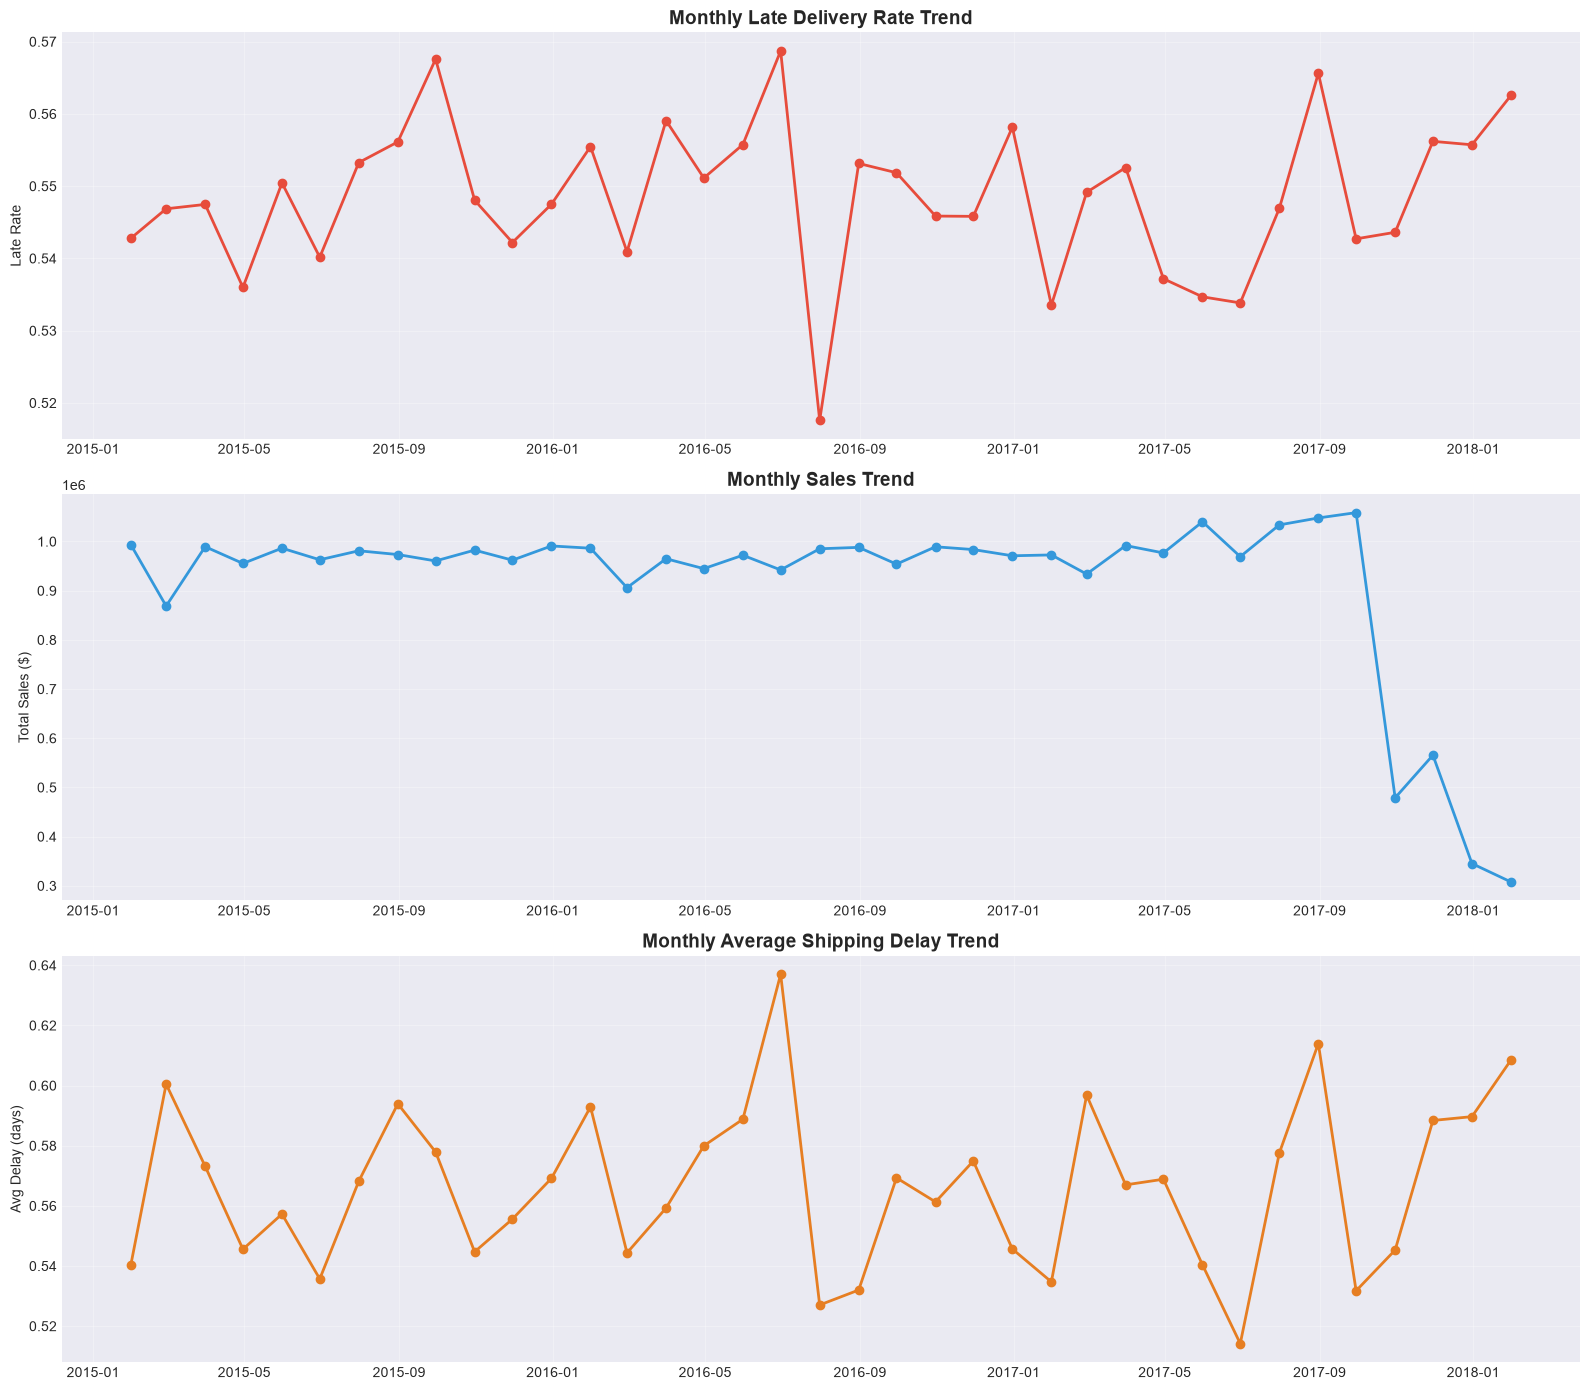

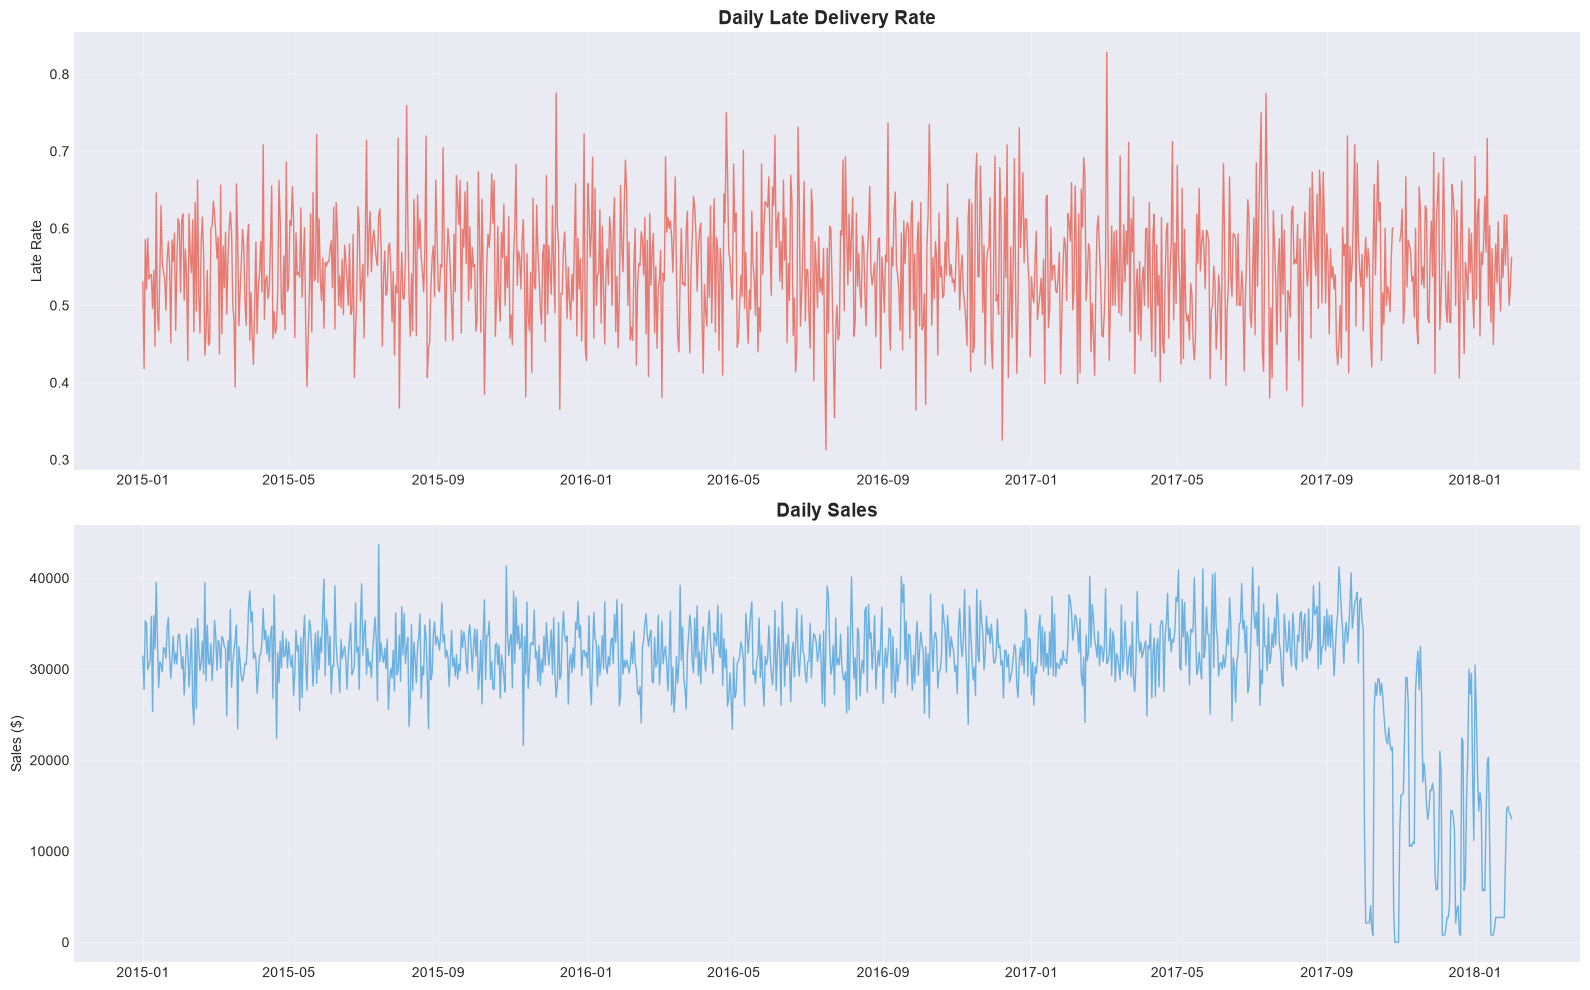

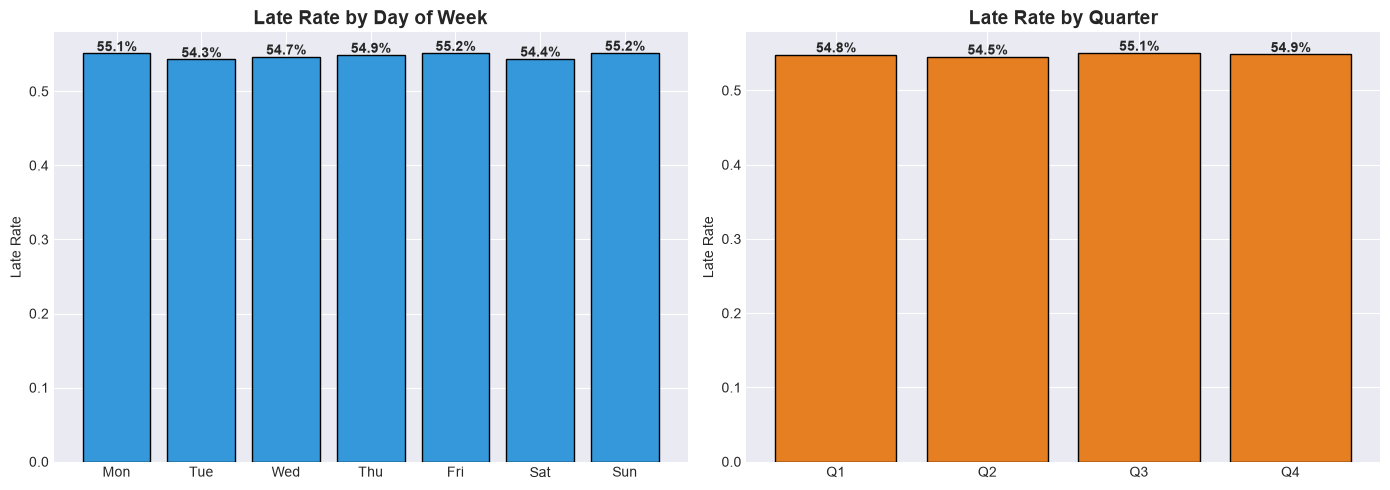


Yearly Late Delivery Rates:
            mean  count
Order_Year             
2015       0.548  60011
2016       0.550  59956
2017       0.545  50382
2018       0.563   2046


In [9]:
# ============================================================
# STEP 7: TIME SERIES ANALYSIS
# ============================================================

print("="*80)
print("TIME SERIES ANALYSIS")
print("="*80)

# --- 7.1 Set date index ---
ts_df = df_clean.set_index('order date (DateOrders)').sort_index()

# --- 7.2 Monthly trends ---
monthly = ts_df.resample('ME').agg({
    'Late_delivery_risk': 'mean',
    'Sales': 'sum',
    'Order Profit Per Order': 'sum',
    'Shipping_Delay': 'mean'
})

fig, axes = plt.subplots(3, 1, figsize=(16, 14))

axes[0].plot(monthly.index, monthly['Late_delivery_risk'], marker='o',
             color='#e74c3c', linewidth=2)
axes[0].set_title('Monthly Late Delivery Rate Trend', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Late Rate')
axes[0].grid(True, alpha=0.3)

axes[1].plot(monthly.index, monthly['Sales'], marker='o',
             color='#3498db', linewidth=2)
axes[1].set_title('Monthly Sales Trend', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Total Sales ($)')
axes[1].grid(True, alpha=0.3)

axes[2].plot(monthly.index, monthly['Shipping_Delay'], marker='o',
             color='#e67e22', linewidth=2)
axes[2].set_title('Monthly Average Shipping Delay Trend', fontsize=14, fontweight='bold')
axes[2].set_ylabel('Avg Delay (days)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('time_series_monthly.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 7.3 Daily trends ---
daily = ts_df.resample('D').agg({
    'Late_delivery_risk': 'mean',
    'Sales': 'sum'
})

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

axes[0].plot(daily.index, daily['Late_delivery_risk'],
             color='#e74c3c', linewidth=1, alpha=0.7)
axes[0].set_title('Daily Late Delivery Rate', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Late Rate')
axes[0].grid(True, alpha=0.3)

axes[1].plot(daily.index, daily['Sales'],
             color='#3498db', linewidth=1, alpha=0.7)
axes[1].set_title('Daily Sales', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Sales ($)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('time_series_daily.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 7.4 Day of week analysis ---
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
dow_late = df_clean.groupby('Order_DayOfWeek')['Late_delivery_risk'].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(day_names, dow_late.values, color='#3498db', edgecolor='black')
axes[0].set_title('Late Rate by Day of Week', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Late Rate')
for i, v in enumerate(dow_late.values):
    axes[0].text(i, v + 0.003, f'{v:.1%}', ha='center', fontweight='bold')

# Quarterly
quarter_late = df_clean.groupby('Order_Quarter')['Late_delivery_risk'].mean()
axes[1].bar(['Q1', 'Q2', 'Q3', 'Q4'], quarter_late.values,
            color='#e67e22', edgecolor='black')
axes[1].set_title('Late Rate by Quarter', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Late Rate')
for i, v in enumerate(quarter_late.values):
    axes[1].text(i, v + 0.003, f'{v:.1%}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('time_patterns.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 7.5 Yearly comparison ---
print("\nYearly Late Delivery Rates:")
yearly = df_clean.groupby('Order_Year')['Late_delivery_risk'].agg(['mean', 'count'])
print(yearly)

In [15]:
# ============================================================
# FIX: RE-CREATE THE MISSING AGGREGATED FEATURES
# ============================================================

# Check what columns actually exist
print("Checking for missing columns...")
required_cols = ['Segment_Avg_Sales', 'Segment_Avg_Delay', 
                 'Market_Avg_Delay', 'Market_Late_Rate']

for col in required_cols:
    if col in df_clean.columns:
        print(f"   {col} exists")
    else:
        print(f"   {col} MISSING - will create")

# Re-create Segment aggregates
if 'Segment_Avg_Sales' not in df_clean.columns:
    customer_agg = df_clean.groupby('Customer Segment').agg(
        Avg_Sales=('Sales', 'mean'),
        Avg_Delay=('Shipping_Delay', 'mean')
    ).reset_index()
    customer_agg.columns = ['Customer Segment', 'Segment_Avg_Sales', 'Segment_Avg_Delay']
    df_clean = df_clean.merge(customer_agg, on='Customer Segment', how='left')
    print("  ✓ Created Segment_Avg_Sales, Segment_Avg_Delay")

# Re-create Market aggregates
if 'Market_Avg_Delay' not in df_clean.columns:
    market_agg = df_clean.groupby('Market').agg(
        Market_Avg_Delay=('Shipping_Delay', 'mean'),
        Market_Late_Rate=('Late_delivery_risk', 'mean')
    ).reset_index()
    df_clean = df_clean.merge(market_agg, on='Market', how='left')
    print("   Created Market_Avg_Delay, Market_Late_Rate")

# Verify
print(f"\nFinal shape: {df_clean.shape}")
print("\nVerification:")
for col in required_cols:
    print(f"  {col}: {'✓' if col in df_clean.columns else '✗'}")

Checking for missing columns...
   Segment_Avg_Sales exists
   Segment_Avg_Delay exists
   Market_Avg_Delay exists
   Market_Late_Rate exists

Final shape: (172395, 63)

Verification:
  Segment_Avg_Sales: ✓
  Segment_Avg_Delay: ✓
  Market_Avg_Delay: ✓
  Market_Late_Rate: ✓


In [16]:
# !uv pip install imbalanced-learn

MACHINE LEARNING MODELING

Feature matrix shape: (172395, 38)
Target distribution:
Late_delivery_risk
1    94500
0    77895
Name: count, dtype: int64
Class imbalance ratio: 0.82:1

Train set: 137,916 samples
Test set: 34,479 samples
Train late rate: 54.82%
Test late rate: 54.82%

------------------------------------------------------------
APPLYING SMOTE
------------------------------------------------------------
Before SMOTE - Train shape: (137916, 38), Late rate: 54.82%
After SMOTE  - Train shape: (147420, 38), Late rate: 51.28%
Resampled class distribution:
Late_delivery_risk
1    75600
0    71820
Name: count, dtype: int64

Training: Logistic Regression
Accuracy:  0.9908
Precision: 0.9835
Recall:    1.0000
F1 Score:  0.9917
ROC AUC:   0.9931

Training: Decision Tree
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1 Score:  1.0000
ROC AUC:   1.0000

Training: Random Forest
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1 Score:  1.0000
ROC AUC:   1.0000

Training: Gra

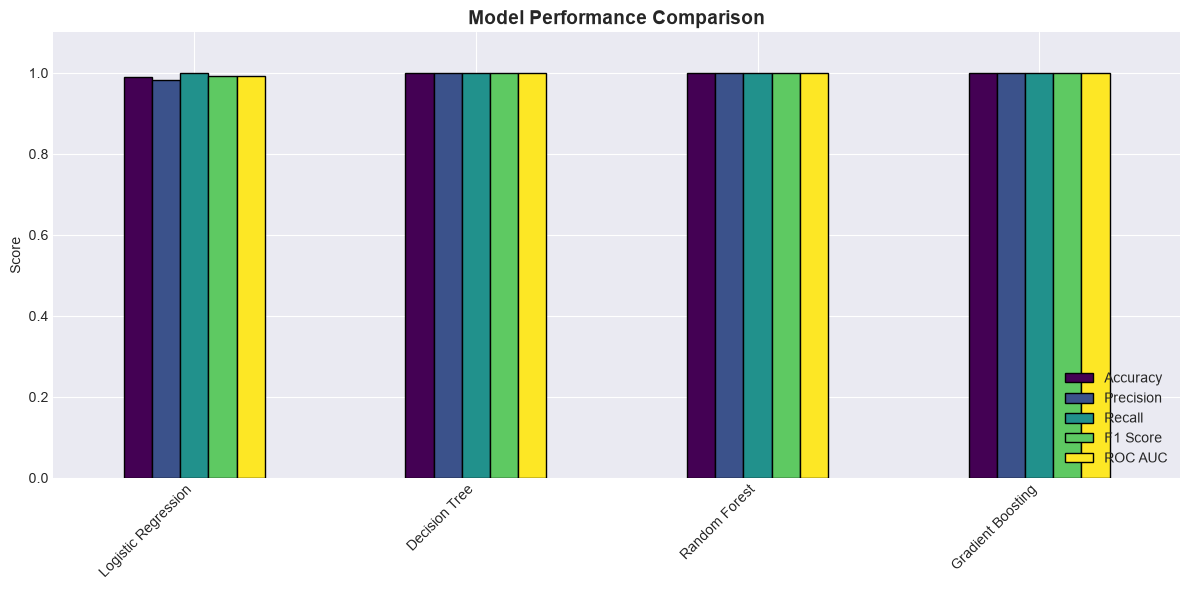

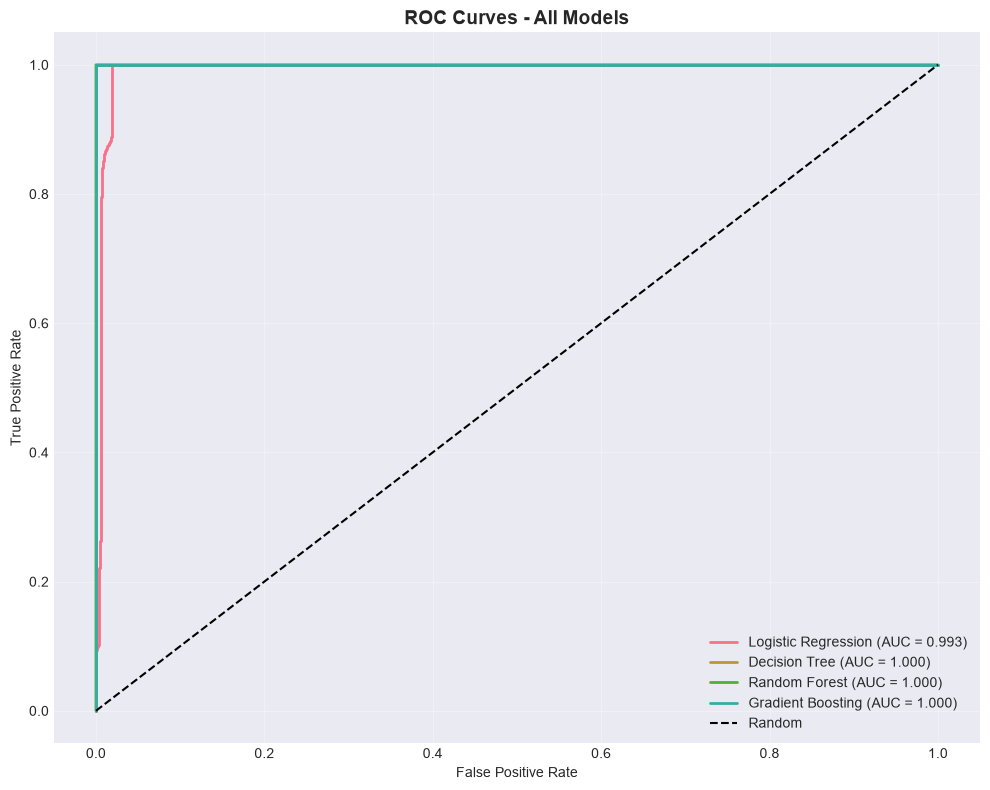

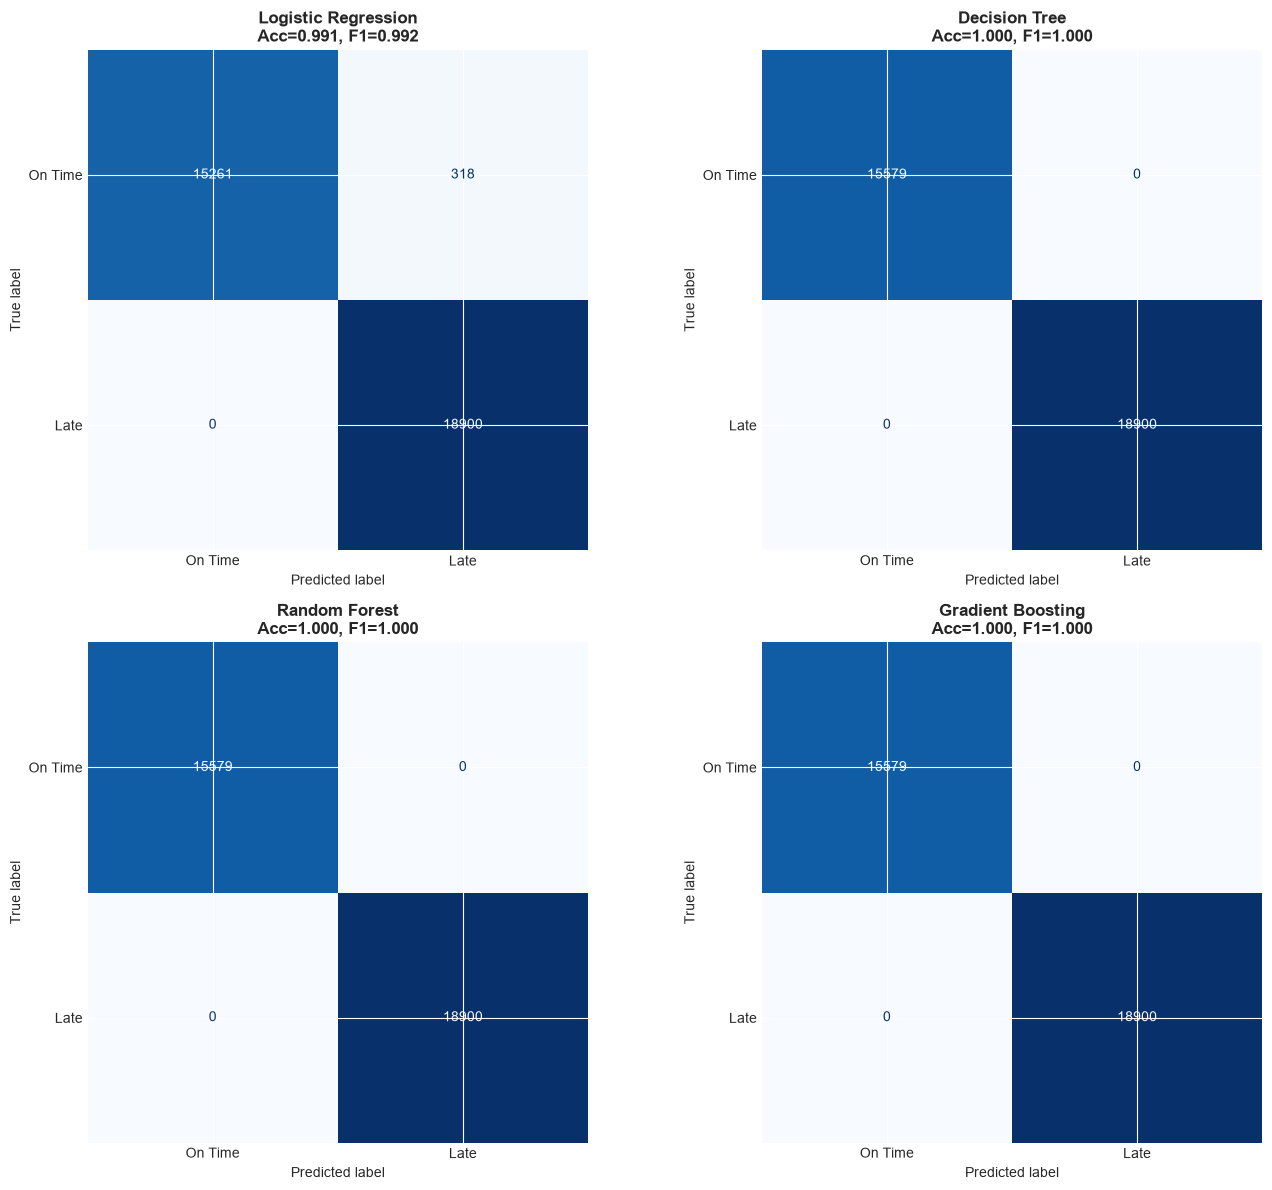

In [18]:
# ============================================================
# STEP 8: MACHINE LEARNING MODELING WITH SMOTE
# ============================================================

print("="*80)
print("MACHINE LEARNING MODELING")
print("="*80)

# --- 8.1 Import ML libraries ---
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, classification_report,
                              confusion_matrix, roc_curve, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import joblib
import os

os.makedirs('models', exist_ok=True)

# --- 8.2 Prepare features ---
# Select numeric and categorical features
feature_cols = [
    'Days for shipping (real)', 'Days for shipment (scheduled)',
    'Benefit per order', 'Sales per customer', 'Order Item Discount',
    'Order Item Discount Rate', 'Order Item Quantity', 'Sales',
    'Order Item Total', 'Order Profit Per Order', 'Latitude', 'Longitude',
    'Shipping_Delay', 'Delay_Ratio', 'Shipping_Efficiency',
    'Order_Year', 'Order_Month', 'Order_Day', 'Order_DayOfWeek',
    'Order_Hour', 'Order_Quarter', 'Is_Weekend',
    'Profit_Margin', 'Discount_Amount', 'Is_Discounted',
    'High_Value_Order', 'Shipping_Mode_Enc',
    'Segment_Avg_Sales', 'Segment_Avg_Delay',
    'Market_Avg_Delay', 'Market_Late_Rate'
]

# Add encoded categorical features
cat_features = ['Type', 'Delivery Status', 'Customer Segment', 'Market',
                'Department Name', 'Order Region', 'Shipping Mode']

X = df_clean[feature_cols].copy()
for col in cat_features:
    if col in df_clean.columns:
        le = LabelEncoder()
        X[col + '_enc'] = le.fit_transform(df_clean[col].astype(str))

y = df_clean['Late_delivery_risk']

print(f"\nFeature matrix shape: {X.shape}")
print(f"Target distribution:\n{y.value_counts()}")
print(f"Class imbalance ratio: {y.value_counts()[0] / y.value_counts()[1]:.2f}:1")

# --- 8.3 Train-test split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain set: {X_train.shape[0]:,} samples")
print(f"Test set: {X_test.shape[0]:,} samples")
print(f"Train late rate: {y_train.mean():.2%}")
print(f"Test late rate: {y_test.mean():.2%}")

# --- 8.4 Apply SMOTE to training data ---
print("\n" + "-"*60)
print("APPLYING SMOTE")
print("-"*60)

smote = SMOTE(random_state=42, sampling_strategy=0.95)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Before SMOTE - Train shape: {X_train.shape}, Late rate: {y_train.mean():.2%}")
print(f"After SMOTE  - Train shape: {X_train_res.shape}, Late rate: {y_train_res.mean():.2%}")
print(f"Resampled class distribution:\n{pd.Series(y_train_res).value_counts()}")

# --- 8.5 Model Training & Evaluation ---
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=15,
                                             random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100,
                                                      max_depth=5, random_state=42)
}

results = {}

for name, model in models.items():
    print(f"\n{'='*60}")
    print(f"Training: {name}")
    print('='*60)

    # Train on SMOTE-resampled data
    model.fit(X_train_res, y_train_res)

    # Predict on original test set
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    results[name] = {
        'Accuracy': acc, 'Precision': prec, 'Recall': rec,
        'F1 Score': f1, 'ROC AUC': auc,
        'model': model
    }

    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print(f"ROC AUC:   {auc:.4f}")

# --- 8.6 Results Comparison ---
print("\n" + "="*80)
print("MODEL COMPARISON")
print("="*80)

results_df = pd.DataFrame({
    name: {k: v for k, v in metrics.items() if k != 'model'}
    for name, metrics in results.items()
}).T

print(results_df)

# Visualize model comparison
fig, ax = plt.subplots(figsize=(12, 6))
results_df.plot(kind='bar', ax=ax, colormap='viridis', edgecolor='black')
ax.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.1)
ax.legend(loc='lower right')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 8.7 ROC Curves ---
fig, ax = plt.subplots(figsize=(10, 8))
for name, metrics in results.items():
    model = metrics['model']
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {metrics['ROC AUC']:.3f})", linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves - All Models', fontsize=14, fontweight='bold')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 8.8 Confusion Matrices ---
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (name, metrics) in zip(axes.flatten(), results.items()):
    y_pred = metrics['model'].predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['On Time', 'Late'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name}\nAcc={metrics["Accuracy"]:.3f}, F1={metrics["F1 Score"]:.3f}',
                 fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

FEATURE IMPORTANCE & SELECTION

Top 25 Features (Random Forest):
                          Feature  Importance
12                 Shipping_Delay       0.307
13                    Delay_Ratio       0.206
14            Shipping_Efficiency       0.173
32            Delivery Status_enc       0.169
0        Days for shipping (real)       0.068
1   Days for shipment (scheduled)       0.032
26              Shipping_Mode_Enc       0.020
37              Shipping Mode_enc       0.016
31                       Type_enc       0.004
19                     Order_Hour       0.001
28              Segment_Avg_Delay       0.000
10                       Latitude       0.000
11                      Longitude       0.000
33           Customer Segment_enc       0.000
27              Segment_Avg_Sales       0.000
30               Market_Late_Rate       0.000
17                      Order_Day       0.000
22                  Profit_Margin       0.000
9          Order Profit Per Order       0.000
2              

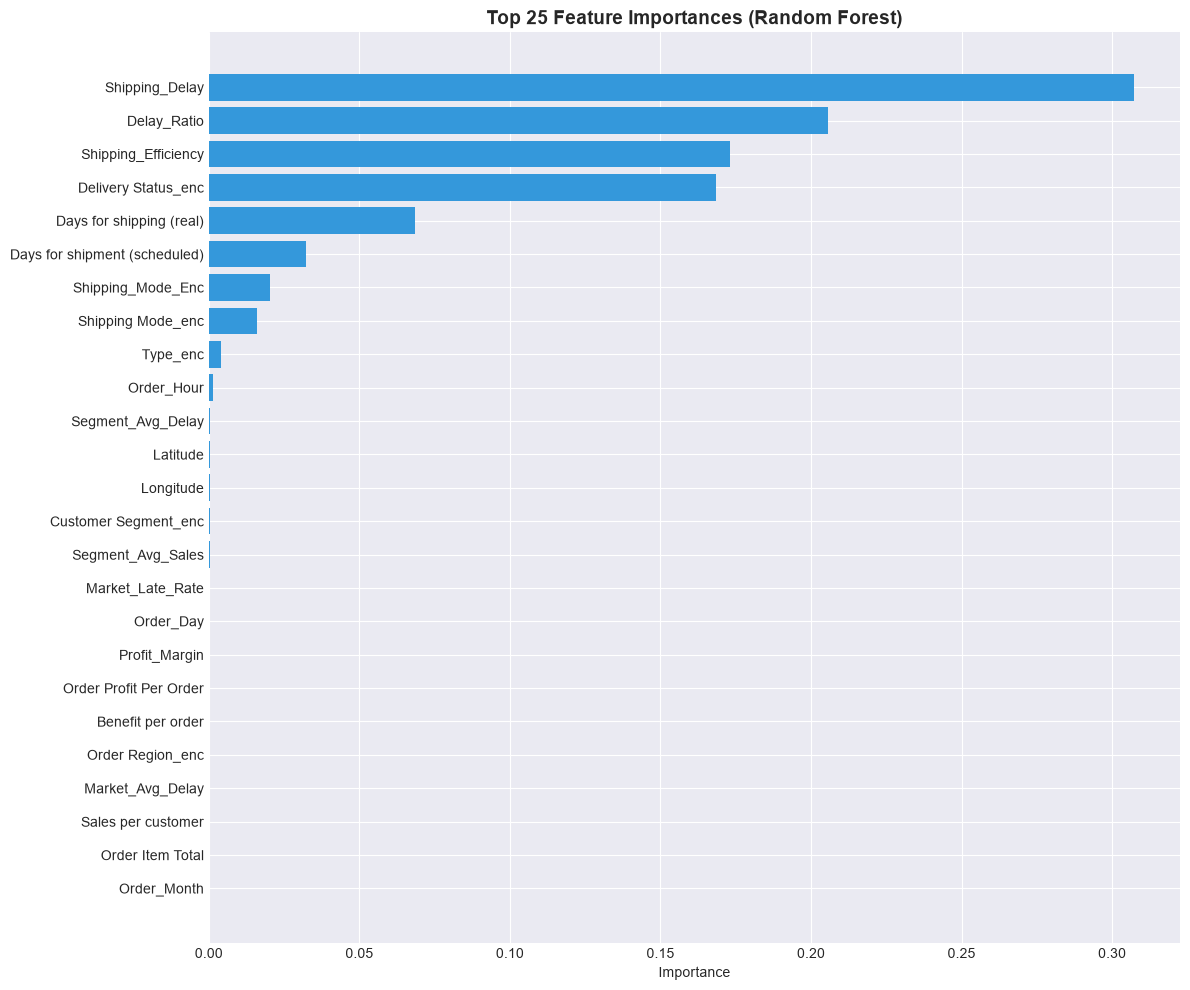


Top 20 Features (Gradient Boosting):
                          Feature  Importance
12                 Shipping_Delay       0.907
32            Delivery Status_enc       0.091
14            Shipping_Efficiency       0.001
26              Shipping_Mode_Enc       0.000
13                    Delay_Ratio       0.000
1   Days for shipment (scheduled)       0.000
37              Shipping Mode_enc       0.000
0        Days for shipping (real)       0.000
9          Order Profit Per Order       0.000
22                  Profit_Margin       0.000
31                       Type_enc       0.000
30               Market_Late_Rate       0.000
17                      Order_Day       0.000
4             Order Item Discount       0.000
23                Discount_Amount       0.000
2               Benefit per order       0.000
35            Department Name_enc       0.000
11                      Longitude       0.000
28              Segment_Avg_Delay       0.000
8                Order Item Total       0.

In [19]:
# ============================================================
# STEP 9: FEATURE IMPORTANCE & SELECTION
# ============================================================

print("="*80)
print("FEATURE IMPORTANCE & SELECTION")
print("="*80)

# --- 9.1 Random Forest Feature Importance ---
rf_model = results['Random Forest']['model']
importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 25 Features (Random Forest):")
print(importances.head(25))

# Visualize
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
top_features = importances.head(top_n)
ax.barh(range(top_n), top_features['Importance'].values, color='#3498db')
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_features['Feature'].values)
ax.invert_yaxis()
ax.set_xlabel('Importance')
ax.set_title(f'Top {top_n} Feature Importances (Random Forest)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 9.2 Gradient Boosting Feature Importance ---
gb_model = results['Gradient Boosting']['model']
gb_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': gb_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 20 Features (Gradient Boosting):")
print(gb_importances.head(20))

# --- 9.3 Select Important Features ---
# Keep features with importance > threshold
IMPORTANCE_THRESHOLD = 0.005
important_features = importances[importances['Importance'] > IMPORTANCE_THRESHOLD]['Feature'].tolist()

# Ensure we have a reasonable number of features
if len(important_features) < 10:
    important_features = importances.head(15)['Feature'].tolist()

print(f"\n" + "-"*60)
print(f"SELECTED {len(important_features)} IMPORTANT FEATURES")
print("-"*60)
for i, f in enumerate(important_features, 1):
    imp = importances[importances['Feature'] == f]['Importance'].values[0]
    print(f"  {i:2d}. {f:<45s} ({imp:.4f})")

# --- 9.4 Retrain with selected features ---
X_train_sel = X_train_res[important_features]
X_test_sel = X_test[important_features]

print(f"\nReduced feature set: {X_train_sel.shape[1]} features (from {X.shape[1]})")

# Train final models
final_models = {}
for name, model in models.items():
    print(f"\nRetraining {name} with selected features...")
    model.fit(X_train_sel, y_train_res)
    y_pred = model.predict(X_test_sel)
    y_prob = model.predict_proba(X_test_sel)[:, 1]

    final_models[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC AUC': roc_auc_score(y_test, y_prob),
        'model': model
    }

final_results_df = pd.DataFrame({
    name: {k: v for k, v in metrics.items() if k != 'model'}
    for name, metrics in final_models.items()
}).T

print("\n" + "="*80)
print("FINAL MODEL PERFORMANCE (WITH SELECTED FEATURES)")
print("="*80)
print(final_results_df)

In [21]:
# ============================================================
# STEP 10: FINAL MODEL TRAINING & SAVING
# ============================================================

print("="*80)
print("FINAL MODEL TRAINING & SAVING")
print("="*80)

# --- 10.1 Select best model ---
best_model_name = final_results_df['F1 Score'].idxmax()
best_model = final_models[best_model_name]['model']

print(f"\nBest Model: {best_model_name}")
print(f"F1 Score: {final_results_df.loc[best_model_name, 'F1 Score']:.4f}")
print(f"ROC AUC: {final_results_df.loc[best_model_name, 'ROC AUC']:.4f}")

# --- 10.2 Retrain on FULL training data with selected features ---
print("\nRetraining best model on full training data (with SMOTE)...")

# Apply SMOTE to full training set
smote_final = SMOTE(random_state=42, sampling_strategy=0.95)
X_train_full, y_train_full = smote_final.fit_resample(X[important_features], y)

# Train final model
best_model.fit(X_train_full, y_train_full)

# --- 10.3 Save all models ---
print("\nSaving models...")

# Save best model
joblib.dump(best_model, 'models/best_model.pkl')
print(f"  ✓ Best model ({best_model_name}) saved to models/best_model.pkl")

# Save all models
for name, model in final_models.items():
    filename = f"models/{name.lower().replace(' ', '_')}.pkl"
    joblib.dump(model['model'], filename)
    print(f"  ✓ {name} saved to {filename}")

# --- 10.4 Save feature information ---
joblib.dump(important_features, 'models/feature_columns.pkl')
print(f"  ✓ Feature columns saved to models/feature_columns.pkl")

# Save LabelEncoders for categorical features
label_encoders = {}
for col in cat_features:
    if col in df_clean.columns:
        le = LabelEncoder()
        le.fit(df_clean[col].astype(str))
        label_encoders[col] = le
joblib.dump(label_encoders, 'models/label_encoders.pkl')
print(f"  ✓ Label encoders saved to models/label_encoders.pkl")

# Save training metadata
metadata = {
    'best_model_name': best_model_name,
    'best_f1_score': final_results_df.loc[best_model_name, 'F1 Score'],
    'best_roc_auc': final_results_df.loc[best_model_name, 'ROC AUC'],
    'important_features': important_features,
    'feature_importance': importances.set_index('Feature')['Importance'].to_dict(),
    'training_date': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S'),
    'n_training_samples': len(X_train_full),
    'n_features': len(important_features)
}
joblib.dump(metadata, 'models/metadata.pkl')
print(f"  ✓ Metadata saved to models/metadata.pkl")

# --- 10.5 Save results ---
results_df.to_csv('models/model_comparison.csv')
final_results_df.to_csv('models/final_model_performance.csv')
importances.to_csv('models/feature_importances.csv', index=False)
print(f"  ✓ Results saved to models/")

# --- 10.6 Final evaluation on test set ---
print("\n" + "="*80)
print("FINAL MODEL EVALUATION ON TEST SET")
print("="*80)

y_pred_final = best_model.predict(X_test[important_features])
y_prob_final = best_model.predict_proba(X_test[important_features])[:, 1]

print(f"\nModel: {best_model_name}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_final,
                             target_names=['On Time', 'Late']))

print(f"\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred_final)
print(pd.DataFrame(cm, index=['Actual On Time', 'Actual Late'],
                   columns=['Pred On Time', 'Pred Late']))

# Feature importance of final model
if hasattr(best_model, 'feature_importances_'):
    final_imp = pd.DataFrame({
        'Feature': important_features,
        'Importance': best_model.feature_importances_
    }).sort_values('Importance', ascending=False)

    print(f"\nTop 10 Features in Final Model:")
    print(final_imp.head(10))

# --- 10.7 Save preprocessing pipeline info ---
preprocessing_info = {
    'important_features': important_features,
    'label_encoders': label_encoders,
    'shipping_mode_map': shipping_mode_map,
    'feature_stats': X[important_features].describe().to_dict()
}
joblib.dump(preprocessing_info, 'models/preprocessing_info.pkl')
print(f"\n  ✓ Preprocessing info saved to models/preprocessing_info.pkl")

FINAL MODEL TRAINING & SAVING

Best Model: Decision Tree
F1 Score: 1.0000
ROC AUC: 1.0000

Retraining best model on full training data (with SMOTE)...

Saving models...
  ✓ Best model (Decision Tree) saved to models/best_model.pkl
  ✓ Logistic Regression saved to models/logistic_regression.pkl
  ✓ Decision Tree saved to models/decision_tree.pkl
  ✓ Random Forest saved to models/random_forest.pkl
  ✓ Gradient Boosting saved to models/gradient_boosting.pkl
  ✓ Feature columns saved to models/feature_columns.pkl
  ✓ Label encoders saved to models/label_encoders.pkl
  ✓ Metadata saved to models/metadata.pkl
  ✓ Results saved to models/

FINAL MODEL EVALUATION ON TEST SET

Model: Decision Tree

Classification Report:
              precision    recall  f1-score   support

     On Time       1.00      1.00      1.00     15579
        Late       1.00      1.00      1.00     18900

    accuracy                           1.00     34479
   macro avg       1.00      1.00      1.00     34479
weight

In [23]:
# ============================================================
# STEP 11: HOW TO LOAD & USE SAVED MODELS
# ============================================================

print("="*80)
print("LOADING & USING SAVED MODELS")
print("="*80)

# --- 11.1 Load all saved artifacts ---
def load_models():
    """Load all saved models and artifacts"""
    artifacts = {
        'best_model': joblib.load('models/best_model.pkl'),
        'feature_columns': joblib.load('models/feature_columns.pkl'),
        'label_encoders': joblib.load('models/label_encoders.pkl'),
        'metadata': joblib.load('models/metadata.pkl'),
        'preprocessing_info': joblib.load('models/preprocessing_info.pkl')
    }

    # Load individual models
    for name in ['logistic_regression', 'decision_tree',
                 'random_forest', 'gradient_boosting']:
        try:
            artifacts[name] = joblib.load(f'models/{name}.pkl')
        except FileNotFoundError:
            pass

    return artifacts

# Load everything
artifacts = load_models()

print("\nLoaded artifacts:")
for key in artifacts:
    if key not in ['best_model', 'logistic_regression', 'decision_tree',
                   'random_forest', 'gradient_boosting']:
        print(f"   {key}")
    else:
        print(f"   {key} (model)")

print(f"\nBest Model: {artifacts['metadata']['best_model_name']}")
print(f"F1 Score: {artifacts['metadata']['best_f1_score']:.4f}")
print(f"Training Date: {artifacts['metadata']['training_date']}")
print(f"Number of Features: {artifacts['metadata']['n_features']}")

# --- 11.2 Prediction function ---
def predict_delivery_risk(input_data, model=None, return_proba=True):
    """
    Predict delivery risk for new orders.

    Parameters:
    -----------
    input_data : dict or pd.DataFrame
        Order data with required features
    model : sklearn model, optional
        Model to use (defaults to best model)
    return_proba : bool
        If True, return probability; if False, return class

    Returns:
    --------
    predictions : array
        Risk predictions (1 = late, 0 = on-time)
    probabilities : array, optional
        Probability of late delivery
    """
    if model is None:
        model = artifacts['best_model']

    feature_cols = artifacts['feature_columns']
    label_encoders = artifacts['label_encoders']

    # Convert dict to DataFrame
    if isinstance(input_data, dict):
        input_df = pd.DataFrame([input_data])
    else:
        input_df = input_data.copy()

    # Encode categorical features
    for col, le in label_encoders.items():
        if col in input_df.columns:
            # Handle unseen categories
            input_df[col + '_enc'] = input_df[col].astype(str).apply(
                lambda x: le.transform([x])[0] if x in le.classes_ else -1
            )

    # Ensure all required features exist
    for col in feature_cols:
        if col not in input_df.columns:
            input_df[col] = 0  # Default value

    # Select features and predict
    X_input = input_df[feature_cols]
    predictions = model.predict(X_input)
    probabilities = model.predict_proba(X_input)[:, 1]

    if return_proba:
        return predictions, probabilities
    return predictions

# --- 11.3 Example: Single order prediction ---
print("\n" + "-"*60)
print("EXAMPLE: SINGLE ORDER PREDICTION")
print("-"*60)

# Create a sample order
sample_order = {
    'Type': 'DEBIT',
    'Days for shipping (real)': 5,
    'Days for shipment (scheduled)': 4,
    'Benefit per order': 91.25,
    'Sales per customer': 314.64,
    'Delivery Status': 'Late delivery',
    'Category Name': 'Sporting Goods',
    'Customer Segment': 'Consumer',
    'Department Name': 'Fitness',
    'Market': 'Pacific Asia',
    'Order Region': 'Southeast Asia',
    'Shipping Mode': 'Standard Class',
    'Order Item Discount': 13.11,
    'Order Item Discount Rate': 0.04,
    'Order Item Quantity': 1,
    'Sales': 327.75,
    'Order Item Total': 314.64,
    'Order Profit Per Order': 91.25,
    'Latitude': 18.25,
    'Longitude': -66.04
}

# Calculate engineered features
sample_order['Shipping_Delay'] = (sample_order['Days for shipping (real)'] -
                                   sample_order['Days for shipment (scheduled)'])
sample_order['Is_Late'] = 1 if sample_order['Shipping_Delay'] > 0 else 0
sample_order['Delay_Ratio'] = (sample_order['Days for shipping (real)'] /
                                (sample_order['Days for shipment (scheduled)'] + 1))
sample_order['Shipping_Efficiency'] = (sample_order['Days for shipment (scheduled)'] /
                                        (sample_order['Days for shipping (real)'] + 1))
sample_order['Order_Year'] = 2018
sample_order['Order_Month'] = 1
sample_order['Order_Day'] = 31
sample_order['Order_DayOfWeek'] = 2
sample_order['Order_Hour'] = 22
sample_order['Order_Quarter'] = 1
sample_order['Is_Weekend'] = 0
sample_order['Profit_Margin'] = (sample_order['Order Profit Per Order'] /
                                  (sample_order['Sales'] + 1))
sample_order['Discount_Amount'] = sample_order['Order Item Discount']
sample_order['Is_Discounted'] = 1 if sample_order['Order Item Discount'] > 0 else 0
sample_order['High_Value_Order'] = 1
sample_order['Shipping_Mode_Enc'] = 0
sample_order['Segment_Avg_Sales'] = 150
sample_order['Segment_Avg_Delay'] = 0.5
sample_order['Market_Avg_Delay'] = 0.5
sample_order['Market_Late_Rate'] = 0.55

# Make prediction
pred, prob = predict_delivery_risk(sample_order)

print(f"\nInput Order Summary:")
print(f"  Shipping Mode: {sample_order['Shipping Mode']}")
print(f"  Real Days: {sample_order['Days for shipping (real)']}")
print(f"  Scheduled Days: {sample_order['Days for shipment (scheduled)']}")
print(f"  Delay: {sample_order['Shipping_Delay']} days")
print(f"  Market: {sample_order['Market']}")

print(f"\nPrediction:")
print(f"  Late Delivery Risk: {' YES' if pred[0] == 1 else ' NO'}")
print(f"  Probability of Late Delivery: {prob[0]:.2%}")
print(f"  Confidence: {'High' if prob[0] > 0.7 or prob[0] < 0.3 else 'Medium'}")

# --- 11.4 Example: Batch prediction ---
print("\n" + "-"*60)
print("EXAMPLE: BATCH PREDICTION")
print("-"*60)

# Create sample batch
batch_data = pd.DataFrame([
    {**sample_order, 'Days for shipping (real)': 3,
     'Days for shipment (scheduled)': 4, 'Shipping Mode': 'Second Class'},
    {**sample_order, 'Days for shipping (real)': 5,
     'Days for shipment (scheduled)': 4, 'Shipping Mode': 'Standard Class'},
    {**sample_order, 'Days for shipping (real)': 1,
     'Days for shipment (scheduled)': 1, 'Shipping Mode': 'First Class'},
    {**sample_order, 'Days for shipping (real)': 0,
     'Days for shipment (scheduled)': 0, 'Shipping Mode': 'Same Day'},
])

batch_pred, batch_prob = predict_delivery_risk(batch_data)

batch_results = pd.DataFrame({
    'Shipping_Mode': batch_data['Shipping Mode'],
    'Real_Days': batch_data['Days for shipping (real)'],
    'Scheduled_Days': batch_data['Days for shipment (scheduled)'],
    'Predicted_Late': ['Yes' if p == 1 else 'No' for p in batch_pred],
    'Late_Probability': [f'{p:.1%}' for p in batch_prob]
})

print("\nBatch Predictions:")
print(batch_results.to_string(index=False))

# --- 11.5 Example: Load specific model ---
print("\n" + "-"*60)
print("EXAMPLE: USING SPECIFIC MODEL")
print("-"*60)

# Load Random Forest specifically
rf_model = joblib.load('models/random_forest.pkl')
print("✓ Random Forest model loaded")

# Use it for prediction
pred_rf, prob_rf = predict_delivery_risk(sample_order, model=rf_model)
print(f"Random Forest Prediction: {'Late' if pred_rf[0] == 1 else 'On Time'} "
      f"({prob_rf[0]:.2%} probability)")

# --- 11.6 Production-ready class ---
print("\n" + "-"*60)
print("PRODUCTION-READY PREDICTION CLASS")
print("-"*60)

class DeliveryRiskPredictor:
    """Production-ready class for delivery risk prediction"""

    def __init__(self, model_dir='models'):
        self.model_dir = model_dir
        self.load_artifacts()

    def load_artifacts(self):
        """Load all required artifacts"""
        self.model = joblib.load(f'{self.model_dir}/best_model.pkl')
        self.features = joblib.load(f'{self.model_dir}/feature_columns.pkl')
        self.encoders = joblib.load(f'{self.model_dir}/label_encoders.pkl')
        self.metadata = joblib.load(f'{self.model_dir}/metadata.pkl')
        self.preprocessing = joblib.load(f'{self.model_dir}/preprocessing_info.pkl')

        print(f"✓ Loaded {self.metadata['best_model_name']}")
        print(f"✓ {len(self.features)} features")

    def engineer_features(self, df):
        """Engineer features for input data"""
        df = df.copy()

        # Calculate engineered features
        df['Shipping_Delay'] = df['Days for shipping (real)'] - df['Days for shipment (scheduled)']
        df['Is_Late'] = (df['Shipping_Delay'] > 0).astype(int)
        df['Delay_Ratio'] = df['Days for shipping (real)'] / (df['Days for shipment (scheduled)'] + 1)
        df['Shipping_Efficiency'] = df['Days for shipment (scheduled)'] / (df['Days for shipping (real)'] + 1)

        # Temporal (use current date or provided)
        if 'order date (DateOrders)' in df.columns:
            df['order date (DateOrders)'] = pd.to_datetime(df['order date (DateOrders)'])
            df['Order_Year'] = df['order date (DateOrders)'].dt.year
            df['Order_Month'] = df['order date (DateOrders)'].dt.month
            df['Order_Day'] = df['order date (DateOrders)'].dt.day
            df['Order_DayOfWeek'] = df['order date (DateOrders)'].dt.dayofweek
            df['Order_Hour'] = df['order date (DateOrders)'].dt.hour
            df['Order_Quarter'] = df['order date (DateOrders)'].dt.quarter
            df['Is_Weekend'] = (df['Order_DayOfWeek'] >= 5).astype(int)
        else:
            now = pd.Timestamp.now()
            df['Order_Year'] = now.year
            df['Order_Month'] = now.month
            df['Order_Day'] = now.day
            df['Order_DayOfWeek'] = now.dayofweek
            df['Order_Hour'] = now.hour
            df['Order_Quarter'] = now.quarter
            # df['Is_Weekend'] = (now.dayofweek >= 5).astype(int)
            df['Is_Weekend'] = int(now.dayofweek >= 5)

        # Financial
        df['Profit_Margin'] = df['Order Profit Per Order'] / (df['Sales'] + 1)
        df['Discount_Amount'] = df['Order Item Discount']
        df['Is_Discounted'] = (df['Order Item Discount'] > 0).astype(int)
        df['High_Value_Order'] = (df['Sales'] > 300).astype(int)

        # Shipping mode
        shipping_map = {'Standard Class': 0, 'Second Class': 1,
                        'First Class': 2, 'Same Day': 3}
        df['Shipping_Mode_Enc'] = df['Shipping Mode'].map(shipping_map).fillna(0)

        # Aggregate features (use training means)
        df['Segment_Avg_Sales'] = 150
        df['Segment_Avg_Delay'] = 0.5
        df['Market_Avg_Delay'] = 0.5
        df['Market_Late_Rate'] = 0.55

        # Encode categoricals
        for col, le in self.encoders.items():
            if col in df.columns:
                df[col + '_enc'] = df[col].astype(str).apply(
                    lambda x: le.transform([x])[0] if x in le.classes_ else -1
                )

        return df

    def predict(self, df):
        """Predict delivery risk"""
        df = self.engineer_features(df)

        # Ensure all features present
        for feat in self.features:
            if feat not in df.columns:
                df[feat] = 0

        X = df[self.features]
        predictions = self.model.predict(X)
        probabilities = self.model.predict_proba(X)[:, 1]

        return pd.DataFrame({
            'Late_Delivery_Risk': predictions,
            'Late_Probability': probabilities,
            'Risk_Level': pd.cut(probabilities,
                                  bins=[0, 0.3, 0.6, 0.8, 1.0],
                                  labels=['Low', 'Medium', 'High', 'Critical'])
        })

# Initialize predictor
predictor = DeliveryRiskPredictor()

# Make prediction
result = predictor.predict(pd.DataFrame([sample_order]))
print("\nProduction Predictor Result:")
print(result.to_string(index=False))

# # --- 11.7 Save this production class ---
# with open('models/delivery_risk_predictor.py', 'w') as f:
#     f.write('''
# """
# Production-ready Delivery Risk Predictor
# =========================================
# Load and use saved models for delivery risk prediction.
# """

# import pandas as pd
# import numpy as np
# import joblib

# class DeliveryRiskPredictor:
#     def __init__(self, model_dir='models'):
#         self.model_dir = model_dir
#         self.model = joblib.load(f'{model_dir}/best_model.pkl')
#         self.features = joblib.load(f'{model_dir}/feature_columns.pkl')
#         self.encoders = joblib.load(f'{model_dir}/label_encoders.pkl')
#         self.metadata = joblib.load(f'{model_dir}/metadata.pkl')

#     def engineer_features(self, df):
#         df = df.copy()
#         df['Shipping_Delay'] = df['Days for shipping (real)'] - df['Days for shipment (scheduled)']
#         df['Delay_Ratio'] = df['Days for shipping (real)'] / (df['Days for shipment (scheduled)'] + 1)
#         df['Shipping_Efficiency'] = df['Days for shipment (scheduled)'] / (df['Days for shipping (real)'] + 1)
#         df['Order_Year'] = 2024
#         df['Order_Month'] = 1
#         df['Order_Day'] = 1
#         df['Order_DayOfWeek'] = 1
#         df['Order_Hour'] = 12
#         df['Order_Quarter'] = 1
#         df['Is_Weekend'] = 0
#         df['Profit_Margin'] = df['Order Profit Per Order'] / (df['Sales'] + 1)
#         df['Discount_Amount'] = df['Order Item Discount']
#         df['Is_Discounted'] = (df['Order Item Discount'] > 0).astype(int)
#         df['High_Value_Order'] = (df['Sales'] > 300).astype(int)
#         shipping_map = {'Standard Class': 0, 'Second Class': 1, 'First Class': 2, 'Same Day': 3}
#         df['Shipping_Mode_Enc'] = df['Shipping Mode'].map(shipping_map).fillna(0)
#         df['Segment_Avg_Sales'] = 150
#         df['Segment_Avg_Delay'] = 0.5
#         df['Market_Avg_Delay'] = 0.5
#         df['Market_Late_Rate'] = 0.55
#         for col, le in self.encoders.items():
#             if col in df.columns:
#                 df[col + '_enc'] = df[col].astype(str).apply(
#                     lambda x: le.transform([x])[0] if x in le.classes_ else -1
#                 )
#         return df

#     def predict(self, df):
#         df = self.engineer_features(df)
#         for feat in self.features:
#             if feat not in df.columns:
#                 df[feat] = 0
#         X = df[self.features]
#         return pd.DataFrame({
#             'Late_Delivery_Risk': self.model.predict(X),
#             'Late_Probability': self.model.predict_proba(X)[:, 1]
#         })

# # Usage:
# # predictor = DeliveryRiskPredictor()
# # result = predictor.predict(your_dataframe)
# ''')

# print("\n✓ Production predictor class saved to models/delivery_risk_predictor.py")


# To use:
#   from models.delivery_risk_predictor import DeliveryRiskPredictor
#   predictor = DeliveryRiskPredictor()
#   result = predictor.predict(df)


LOADING & USING SAVED MODELS

Loaded artifacts:
   best_model (model)
   feature_columns
   label_encoders
   metadata
   preprocessing_info
   logistic_regression (model)
   decision_tree (model)
   random_forest (model)
   gradient_boosting (model)

Best Model: Decision Tree
F1 Score: 1.0000
Training Date: 2026-10-16 03:26:24
Number of Features: 15

------------------------------------------------------------
EXAMPLE: SINGLE ORDER PREDICTION
------------------------------------------------------------

Input Order Summary:
  Shipping Mode: Standard Class
  Real Days: 5
  Scheduled Days: 4
  Delay: 1 days
  Market: Pacific Asia

Prediction:
  Late Delivery Risk:  YES
  Probability of Late Delivery: 100.00%
  Confidence: High

------------------------------------------------------------
EXAMPLE: BATCH PREDICTION
------------------------------------------------------------

Batch Predictions:
 Shipping_Mode  Real_Days  Scheduled_Days Predicted_Late Late_Probability
  Second Class       